<style>
.lab-banner {
  padding: 28px 32px;
  border-radius: 18px;
  background: linear-gradient(120deg, #0f172a, #1d4ed8, #7c3aed);
  color: white;
  margin: 8px 0 22px 0;
  box-shadow: 0 10px 30px rgba(15, 23, 42, .18);
}
.lab-banner h1 { margin: 0 0 8px 0; font-size: 34px; }
.lab-banner p { margin: 5px 0; font-size: 16px; opacity: .95; }
.note-box, .why-box, .warning-box, .result-box {
  padding: 14px 18px; border-radius: 12px; margin: 12px 0;
}
.note-box { background: #eff6ff; border-left: 5px solid #2563eb; }
.why-box { background: #f5f3ff; border-left: 5px solid #7c3aed; }
.warning-box { background: #fff7ed; border-left: 5px solid #ea580c; }
.result-box { background: #ecfdf5; border-left: 5px solid #059669; }
.small-muted { color: #64748b; font-size: 13px; }
</style>

<div class="lab-banner">
  <h1>LAB07 — TEXT CLASSIFICATION · UNIFIED GPU COLAB · PROTOBUF FIX</h1>
  <p><b>Assignment 1:</b> Phân tích cảm xúc IMDB bằng TensorFlow/Keras</p>
  <p><b>Assignment 2:</b> Phân loại bài báo BBC bằng TF-IDF và Doc2Vec</p>
  <p class="small-muted" style="color:#e2e8f0">Bản hợp nhất duy nhất, đã sửa xung đột Protobuf và tối ưu cho Google Colab GPU: TensorFlow mixed precision, pipeline tf.data có cache/prefetch và XGBoost CUDA với cơ chế tự động fallback CPU.</p>
</div>

### Thông tin sinh viên
- **Họ và tên:** ........................................................
- **MSSV:** ........................................................
- **Lớp:** ........................................................
- **Ngày thực hiện:** ........................................................


## Mục tiêu học tập

Sau khi hoàn thành notebook, người học có thể:

1. Mô tả quy trình phân loại văn bản từ dữ liệu thô đến dự đoán.
2. Phân biệt **tokenization**, **TF-IDF**, **embedding** và **Doc2Vec**.
3. Xây dựng mô hình nhị phân cho IMDB bằng TensorFlow/Keras.
4. Xây dựng mô hình đa lớp cho BBC News bằng scikit-learn, Gensim và XGBoost.
5. Đọc và giải thích đường học, ma trận nhầm lẫn, Accuracy và Macro-F1.
6. Nhận biết các lỗi kỹ thuật thường gặp như API cũ, data leakage và đánh giá chưa đầy đủ.

<div class="why-box"><b>Lý do thiết kế notebook theo dạng này:</b> Bài lab không chỉ cần “chạy ra kết quả” mà còn phải thể hiện người làm hiểu dữ liệu, hiểu mô hình, biết đánh giá và biết giải thích quyết định kỹ thuật.</div>

## Các điểm đã sửa so với tài liệu gốc

| Nội dung cũ | Cách triển khai lại | Lý do |
|---|---|---|
| Cài `tf-nightly` | Dùng TensorFlow ổn định có sẵn trên Colab | Bản nightly thay đổi thường xuyên, dễ lỗi phụ thuộc |
| `imdb_reviews/subwords8k` và `encoder` | `imdb_reviews` + `TextVectorization` | API hiện đại, dễ đóng gói vào mô hình, xử lý văn bản thô trực tiếp |
| Padding thủ công bằng `padded_batch` | `output_sequence_length` trong `TextVectorization` | Luồng dữ liệu đơn giản và nhất quán |
| Chỉ theo dõi Accuracy | Thêm Loss, Macro-F1, classification report và confusion matrix | Accuracy một mình chưa chỉ ra lớp nào bị nhầm |
| Huấn luyện Doc2Vec theo vòng lặp giảm `alpha` thủ công | Dùng API `build_vocab()` và `train()` hiện hành | Phù hợp Gensim 4.x, ít lỗi hơn |
| Dễ vô tình học từ tập kiểm tra | Tách train/test trước khi fit vectorizer/Doc2Vec | Ngăn **data leakage** |
| Không kiểm soát thời gian chạy | Có `QUICK_MODE` | Dễ kiểm thử; có thể chuyển sang chế độ đầy đủ khi nộp |

![Quy trình phân loại văn bản](attachment:pipeline.png)

**Giải thích hình:** Văn bản không được đưa thẳng vào thuật toán học máy. Ta cần làm sạch và biến nó thành số. Sau khi mô hình học trên tập huấn luyện, tập kiểm tra chỉ được dùng để ước lượng khả năng tổng quát hoá trên dữ liệu chưa từng thấy.

## 0. Hướng dẫn chạy bản hợp nhất GPU

1. Mở notebook bằng **Google Colab**.
2. Chọn `Runtime → Change runtime type → T4 GPU` (hoặc GPU mạnh hơn nếu tài khoản có).
3. Chọn `Runtime → Run all`; không cần chạy ghép với bất kỳ notebook nào khác.
4. Bản này mặc định `QUICK_MODE = False` để chạy đầy đủ dữ liệu và cấu hình.
5. Khi chỉ cần kiểm tra nhanh luồng code, tạm đổi `QUICK_MODE = True` rồi chạy lại từ đầu.
6. Nếu đã từng chạy bản cũ và gặp lỗi Protobuf, chọn **Runtime → Restart session** trước khi chạy bản này.

<div class="warning-box"><b>Lưu ý:</b> TensorFlow và XGBoost sẽ tự dùng GPU khi Colab cấp GPU. Logistic Regression, Random Forest và Gensim Doc2Vec không có backend GPU trong các thư viện đang dùng, nên chúng vẫn tận dụng toàn bộ CPU Colab. Nếu Colab chưa cấp GPU, notebook sẽ cảnh báo và vẫn có thể chạy bằng CPU.</div>


# PHẦN A — CHUẨN BỊ MÔI TRƯỜNG

In [21]:
# Cài/kiểm tra thư viện tương thích với Google Colab.
# QUAN TRỌNG: đồng bộ Protobuf TRƯỚC KHI import TensorFlow Datasets.
# tensorflow-metadata hiện chứa gencode Protobuf 6.31.1; runtime cũ hơn sẽ lỗi import.

import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

try:
    from packaging.version import Version
except ImportError:
    subprocess.check_call(
        [sys.executable, '-m', 'pip', 'install', '-q', 'packaging']
    )
    from packaging.version import Version


PACKAGE_RULES = {
    # module_name: (distribution_name, minimum_version, install_spec)
    # Ghim đúng runtime 6.31.1 để khớp gencode của tensorflow-metadata,
    # đồng thời tránh pip tự chọn lại Protobuf 5.x.
    'google.protobuf': (
        'protobuf',
        '6.31.1',
        'protobuf==6.31.1',
    ),
    'tensorflow': (
        'tensorflow',
        '2.16.0',
        'tensorflow>=2.16,<3',
    ),
    'tensorflow_datasets': (
        'tensorflow-datasets',
        '4.9.0',
        'tensorflow-datasets>=4.9,<5',
    ),
    # Bảo đảm TFDS dùng tensorflow-metadata đã hỗ trợ Protobuf 6.x.
    'tensorflow_metadata': (
        'tensorflow-metadata',
        '1.17.2',
        'tensorflow-metadata>=1.17.2,<2',
    ),
    'gensim': (
        'gensim',
        '4.4.0',
        'gensim>=4.4,<5',
    ),
    'wordcloud': (
        'wordcloud',
        '1.9.3',
        'wordcloud>=1.9.3,<2',
    ),
    'xgboost': (
        'xgboost',
        '2.1.1',
        'xgboost>=2.1.1,<4',
    ),
}


to_install = []

for module_name, (
    distribution_name,
    minimum_version,
    install_spec,
) in PACKAGE_RULES.items():

    try:
        installed_version = metadata.version(distribution_name)
    except metadata.PackageNotFoundError:
        to_install.append(install_spec)
        continue

    # Riêng Protobuf phải đúng 6.31.1, không chỉ đạt phiên bản tối thiểu.
    if distribution_name == 'protobuf':
        if Version(installed_version) != Version('6.31.1'):
            to_install.append(install_spec)
    elif Version(installed_version) < Version(minimum_version):
        to_install.append(install_spec)


if to_install:
    print('Đang đồng bộ thư viện:', to_install)
    subprocess.check_call([
        sys.executable,
        '-m',
        'pip',
        'install',
        '-q',
        '--upgrade-strategy',
        'only-if-needed',
        *to_install,
    ])
else:
    print('Các thư viện đã đúng phiên bản yêu cầu.')


# Xác nhận Protobuf trên đĩa trước khi import TensorFlow/TFDS.
protobuf_version = metadata.version('protobuf')
if Version(protobuf_version) != Version('6.31.1'):
    raise RuntimeError(
        'Không thể đồng bộ protobuf==6.31.1. '
        f'Phiên bản hiện tại: {protobuf_version}'
    )


pip_check = subprocess.run(
    [sys.executable, '-m', 'pip', 'check'],
    text=True,
    capture_output=True,
    check=False,
)

print('\npip check:')
print(
    pip_check.stdout.strip()
    or pip_check.stderr.strip()
    or 'Không phát hiện xung đột dependency.'
)

print('\nPhiên bản được sử dụng:')
for _, (
    distribution_name,
    _,
    _,
) in PACKAGE_RULES.items():
    try:
        print(f'{distribution_name}: {metadata.version(distribution_name)}')
    except metadata.PackageNotFoundError:
        print(f'{distribution_name}: chưa cài')


Các thư viện đã đúng phiên bản yêu cầu.

pip check:
ipython 7.34.0 requires jedi, which is not installed.
google-ai-generativelanguage 0.6.15 has requirement protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.31.1.
grpcio-status 1.71.2 has requirement protobuf<6.0dev,>=5.26.1, but you have protobuf 6.31.1.

Phiên bản được sử dụng:
protobuf: 6.31.1
tensorflow: 2.20.0
tensorflow-datasets: 4.9.10
tensorflow-metadata: 1.21.0
gensim: 4.4.0
wordcloud: 1.9.6
xgboost: 3.3.0


In [22]:
import os
import re
import string
import time
import random
import warnings
import zlib
import importlib.metadata as metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, mixed_precision

try:
    import tensorflow_datasets as tfds
except Exception as exc:
    message = str(exc)
    if 'Gencode/Runtime' in message or 'runtime cannot be older' in message.lower():
        raise RuntimeError(
            'Phiên Colab hiện tại đã nạp Protobuf cũ vào bộ nhớ. '
            'Chọn Runtime → Restart session, sau đó Run all từ đầu.'
        ) from exc
    raise

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from gensim.utils import simple_preprocess
from wordcloud import WordCloud
from xgboost import XGBClassifier

# Không ẩn toàn bộ warning: warning hội tụ hoặc dependency có thể rất hữu ích.
warnings.filterwarnings('default')

print('TensorFlow:', tf.__version__)
print('TensorFlow Datasets:', metadata.version('tensorflow-datasets'))
print('TensorFlow Metadata:', metadata.version('tensorflow-metadata'))
print('Protobuf:', metadata.version('protobuf'))


TensorFlow: 2.20.0
TensorFlow Datasets: 4.9.10
TensorFlow Metadata: 1.21.0
Protobuf: 6.31.1


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
# =========================
# CẤU HÌNH THÍ NGHIỆM + GPU
# =========================

SEED = 42

# False = chạy đầy đủ để lấy kết quả cuối.
# True  = chỉ kiểm tra nhanh toàn bộ pipeline.
QUICK_MODE = False

CPU_WORKERS = max(1, os.cpu_count() or 1)
DOC2VEC_WORKERS = CPU_WORKERS

# Phát hiện GPU trước khi tạo model/tensor lớn.
GPU_DEVICES = tf.config.list_physical_devices('GPU')
GPU_AVAILABLE = len(GPU_DEVICES) > 0

if GPU_AVAILABLE:
    for gpu in GPU_DEVICES:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            # GPU đã được khởi tạo trước đó; tiếp tục với cấu hình hiện tại.
            pass

    # mixed_float16 tăng tốc đáng kể trên GPU Colab có Tensor Cores.
    mixed_precision.set_global_policy('mixed_float16')

    try:
        tf.config.experimental.enable_tensor_float_32_execution(True)
    except Exception:
        pass
else:
    mixed_precision.set_global_policy('float32')

# Cố định seed nhưng KHÔNG bật deterministic ops,
# vì deterministic kernels thường làm GPU chậm hơn và có thể thiếu hỗ trợ.
keras.utils.set_random_seed(SEED)

# Gensim có thể dùng hàm hash khi khởi tạo trọng số.
def stable_hash(value):
    return zlib.crc32(str(value).encode('utf-8'))

# Kiểm tra XGBoost CUDA bằng một bài toán rất nhỏ.
# Nếu wheel/runtime không hỗ trợ CUDA, tự động chuyển về CPU.
XGB_DEVICE = 'cpu'

if GPU_AVAILABLE:
    try:
        _xgb_probe = XGBClassifier(
            n_estimators=1,
            max_depth=1,
            tree_method='hist',
            device='cuda',
            random_state=SEED,
            verbosity=0,
        )
        _xgb_probe.fit(
            np.array([[0.0], [1.0], [0.1], [0.9]], dtype=np.float32),
            np.array([0, 1, 0, 1], dtype=np.int32),
        )
        XGB_DEVICE = 'cuda'
        del _xgb_probe
    except Exception as exc:
        print('XGBoost CUDA không khả dụng, chuyển sang CPU:', exc)

print('Chế độ:', 'NHANH' if QUICK_MODE else 'ĐẦY ĐỦ')
print('CPU workers:', CPU_WORKERS)
print('TensorFlow GPU:', GPU_AVAILABLE)
print('GPU devices:', GPU_DEVICES if GPU_AVAILABLE else 'Không có')
print('Mixed precision policy:', mixed_precision.global_policy())
print('XGBoost device:', XGB_DEVICE)

if not GPU_AVAILABLE:
    print(
        '\nCẢNH BÁO: Colab chưa cấp GPU. '
        'Hãy chọn Runtime → Change runtime type → T4 GPU rồi Run all lại.'
    )


Chế độ: ĐẦY ĐỦ
CPU workers: 2
TensorFlow GPU: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">
XGBoost device: cuda


<div class="why-box"><b>Tại sao cần cố định seed?</b> Một số bước như chia dữ liệu, khởi tạo trọng số và lấy mẫu có yếu tố ngẫu nhiên. Cố định seed giúp kết quả dễ tái lập, thuận tiện khi so sánh mô hình hoặc viết báo cáo.</div>

# PHẦN B — ASSIGNMENT 1: IMDB MOVIE REVIEWS

## 1. Bài toán và lý thuyết nền

Mỗi review được gán một trong hai nhãn:

- `0`: cảm xúc **tiêu cực**
- `1`: cảm xúc **tích cực**

Đây là bài toán **binary classification**. Mô hình trả về xác suất $p(y=1\mid x)$ bằng hàm sigmoid. Hàm mất mát thường dùng là Binary Cross-Entropy:

$$
\mathcal{L}=-\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

Loss phạt mạnh khi mô hình dự đoán rất tự tin nhưng sai.

## 2. Tải và chia dữ liệu IMDB

Bộ IMDB có 25.000 review huấn luyện và 25.000 review kiểm tra. Ta tách 20% tập train thành validation:

- **Train:** cập nhật trọng số.
- **Validation:** chọn epoch và phát hiện overfitting.
- **Test:** đánh giá cuối cùng; không dùng để điều chỉnh mô hình.

<div class="why-box"><b>Lý do tách ba tập:</b> Nếu vừa nhìn kết quả test vừa sửa mô hình, tập test không còn đại diện cho dữ liệu hoàn toàn mới nữa.</div>

In [24]:
(train_raw, val_raw, test_raw), imdb_info = tfds.load(
    'imdb_reviews',
    split=['train[:80%]', 'train[80%:]', 'test'],
    as_supervised=True,
    with_info=True,
)

# QUICK_MODE dùng mẫu nhỏ hơn để kiểm thử notebook nhanh.
if QUICK_MODE:
    train_raw = train_raw.shuffle(20_000, seed=SEED, reshuffle_each_iteration=False).take(6_000)
    val_raw = val_raw.shuffle(5_000, seed=SEED, reshuffle_each_iteration=False).take(1_500)
    test_raw = test_raw.shuffle(25_000, seed=SEED, reshuffle_each_iteration=False).take(2_500)

print(imdb_info)

tfds.core.DatasetInfo(
    name='imdb_reviews',
    full_name='imdb_reviews/plain_text/1.0.0',
    description="""
    Large Movie Review Dataset. This is a dataset for binary sentiment
    classification containing substantially more data than previous benchmark
    datasets. We provide a set of 25,000 highly polar movie reviews for training,
    and 25,000 for testing. There is additional unlabeled data for use as well.
    """,
    config_description="""
    Plain text
    """,
    homepage='http://ai.stanford.edu/~amaas/data/sentiment/',
    data_dir='/root/tensorflow_datasets/imdb_reviews/plain_text/1.0.0',
    file_format=tfrecord,
    download_size=80.23 MiB,
    dataset_size=129.83 MiB,
    features=FeaturesDict({
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
        'text': Text(shape=(), dtype=string),
    }),
    supervised_keys=('text', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_e

In [25]:
def tf_dataset_to_frame(dataset, max_items=2_000):
    rows = []
    for text, label in tfds.as_numpy(dataset.take(max_items)):
        decoded = text.decode('utf-8') if isinstance(text, bytes) else str(text)
        rows.append({'text': decoded, 'label': int(label)})
    return pd.DataFrame(rows)

imdb_preview = tf_dataset_to_frame(train_raw, max_items=2_000)
imdb_preview['sentiment'] = imdb_preview['label'].map({0: 'Negative', 1: 'Positive'})
imdb_preview['word_count'] = imdb_preview['text'].str.split().str.len()

print('Số mẫu dùng để khám phá:', len(imdb_preview))
display(imdb_preview.head(3))

Số mẫu dùng để khám phá: 2000


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,text,label,sentiment,word_count
0,This was an absolutely terrible movie. Don't b...,0,Negative,116
1,"I have been known to fall asleep during films,...",0,Negative,112
2,Mann photographs the Alberta Rocky Mountains i...,0,Negative,132


## 3. Khám phá dữ liệu IMDB

Ta kiểm tra phân bố nhãn và độ dài review trước khi chọn cấu hình mô hình.

- Nếu nhãn lệch mạnh, Accuracy có thể gây hiểu nhầm.
- Độ dài review giúp chọn `output_sequence_length`: quá ngắn làm mất thông tin, quá dài làm tăng thời gian và bộ nhớ.

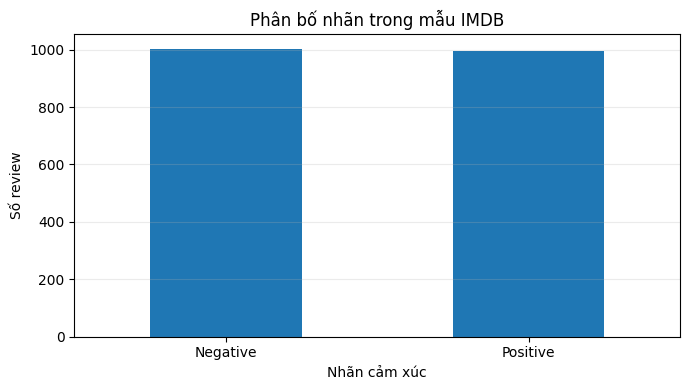

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [26]:
label_counts = imdb_preview['sentiment'].value_counts().sort_index()

plt.figure(figsize=(7, 4))
label_counts.plot(kind='bar')
plt.title('Phân bố nhãn trong mẫu IMDB')
plt.xlabel('Nhãn cảm xúc')
plt.ylabel('Số review')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

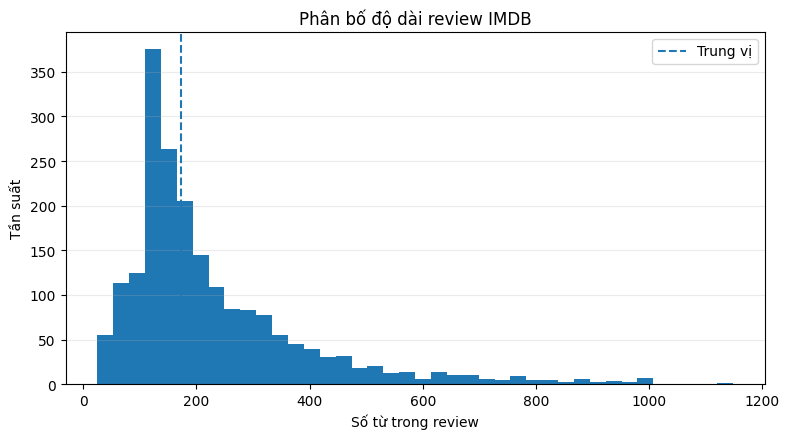

count    2000.000000
mean      229.243500
std       166.022818
min        25.000000
50%       173.000000
75%       282.000000
90%       435.100000
95%       575.050000
max      1148.000000
Name: word_count, dtype: float64


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [27]:
plt.figure(figsize=(8, 4.5))
plt.hist(imdb_preview['word_count'], bins=40)
plt.axvline(imdb_preview['word_count'].median(), linestyle='--', label='Trung vị')
plt.title('Phân bố độ dài review IMDB')
plt.xlabel('Số từ trong review')
plt.ylabel('Tần suất')
plt.legend()
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(imdb_preview['word_count'].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))

<div class="result-box"><b>Cách đọc biểu đồ:</b> Đường đứt là độ dài trung vị. Phần đuôi bên phải cho thấy một số review rất dài. Ta không nhất thiết giữ toàn bộ chiều dài; giới hạn chuỗi là sự đánh đổi giữa lượng thông tin và chi phí tính toán.</div>

In [28]:
# Xem một số ví dụ để hiểu dữ liệu thật sự chứa gì.
for idx, row in imdb_preview.sample(3, random_state=SEED).iterrows():
    print('=' * 100)
    print('Nhãn:', row['sentiment'])
    print(row['text'][:700], '...')

Nhãn: Positive
A solid, if unremarkable film. Matthau, as Einstein, was wonderful. My favorite part, and the only thing that would make me go out of my way to see this again, was the wonderful scene with the physicists playing badmitton, I loved the sweaters and the conversation while they waited for Robbins to retrieve the birdie. ...
Nhãn: Positive
Super Mario 64 is undoubtedly the greatest game ever created. It is so addicting that you could play it for hours upon hours without stopping for a break. I've beaten the game 4 times, but I've never gotten all 120 stars...(I've gotten 111)...but I hope to achieve them eventually. Even though I didn't officially play this game until I was seven in, I loved watching my sisters play it. Now I am 13 and still play this, erasing games and starting over again.<br /><br />The graphics are unbelievable for an early N64 game. The gameplay is addictive. The controls are great. The levels are tough, but not impossible. The Bowser fights are challeng

## 4. Chuẩn hoá và vector hoá văn bản

Máy học không hiểu trực tiếp chuỗi ký tự. `TextVectorization` thực hiện:

1. Viết thường.
2. Bỏ thẻ HTML như `<br />`.
3. Bỏ dấu câu.
4. Tách từ.
5. Ánh xạ từ sang chỉ số nguyên.
6. Cắt hoặc padding chuỗi về cùng chiều dài.

Các token đặc biệt thường gồm:

- `""`: padding.
- `[UNK]`: từ không có trong từ điển.

<div class="why-box"><b>Tại sao dùng TextVectorization thay encoder cũ?</b> Lớp này là một phần của mô hình Keras, có thể nhận văn bản thô khi dự đoán và giảm nguy cơ preprocessing lúc train khác preprocessing lúc triển khai.</div>

In [29]:
MAX_TOKENS = 20_000 if QUICK_MODE else 30_000
SEQUENCE_LENGTH = 250
EMBEDDING_DIM = 96 if QUICK_MODE else 128

@keras.utils.register_keras_serializable()
def custom_standardization(text):
    text = tf.strings.lower(text)
    text = tf.strings.regex_replace(text, r'<br\s*/?>', ' ')
    return tf.strings.regex_replace(
        text,
        f'[{re.escape(string.punctuation)}]',
        ''
    )

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize=custom_standardization,
    output_mode='int',
    output_sequence_length=SEQUENCE_LENGTH,
    name='text_vectorization',
)

# Chỉ học từ điển từ tập train để tránh data leakage.
# Batch lớn + prefetch giúp phần chuẩn bị dữ liệu không làm GPU phải chờ.
adapt_text_ds = (
    train_raw
    .map(lambda text, label: text, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(1024)
    .prefetch(tf.data.AUTOTUNE)
)
vectorizer.adapt(adapt_text_ds)

vocabulary = vectorizer.get_vocabulary()
print('Kích thước từ điển thực tế:', len(vocabulary))
print('20 token đầu:', vocabulary[:20])


Kích thước từ điển thực tế: 30000
20 token đầu: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('was'), np.str_('as'), np.str_('for'), np.str_('with'), np.str_('movie'), np.str_('but'), np.str_('film')]


In [30]:
# Minh hoạ một review được biến thành dãy số như thế nào.
sample_text = imdb_preview.iloc[0]['text']
sample_ids = vectorizer(tf.constant([sample_text]))[0].numpy()

rows = []
for position, token_id in enumerate(sample_ids[:40]):
    token = vocabulary[token_id] if token_id < len(vocabulary) else '[OUT]'
    rows.append({'Vị trí': position, 'Token ID': int(token_id), 'Token': token})

print('Văn bản mẫu:')
print(sample_text[:500], '...')
display(pd.DataFrame(rows))

Văn bản mẫu:
This was an absolutely terrible movie. Don't be lured in by Christopher Walken or Michael Ironside. Both are great actors, but this must simply be their worst role in history. Even their great acting could not redeem this movie's ridiculous storyline. This movie is an early nineties US propaganda piece. The most pathetic scenes were those when the Columbian rebels were making their cases for revolutions. Maria Conchita Alonso appeared phony, and her pseudo-love affair with Walken was nothing but ...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Vị trí,Token ID,Token
0,0,11,this
1,1,13,was
2,2,33,an
3,3,415,absolutely
4,4,370,terrible
5,5,17,movie
6,6,89,dont
7,7,26,be
8,8,10110,lured
9,9,8,in


<div class="note-box"><b>Giải thích bảng token:</b> Mỗi từ đã trở thành một số nguyên. Các số này chưa mang ý nghĩa “gần/xa”; lớp Embedding ở bước kế tiếp sẽ học vector liên tục cho từng token.</div>

## 5. Kiến trúc mô hình GPU


### Vai trò từng lớp

- **TextVectorization (tiền xử lý):** đổi chuỗi thành dãy token ID trước khi batch được đưa vào model.
- **Embedding:** học vector cho mỗi token.
- **SpatialDropout1D:** bỏ đồng thời một số chiều embedding để giảm overfitting.
- **Conv1D:** học các mẫu từ/cụm từ cục bộ và khai thác GPU tốt hơn mô hình Dense rất nhỏ.
- **GlobalMaxPooling1D:** giữ đặc trưng mạnh nhất trên toàn review.
- **Dense + Dropout:** kết hợp đặc trưng và giảm học thuộc.
- **Sigmoid `float32`:** trả xác suất ổn định ngay cả khi các lớp trước chạy mixed precision.

<div class="why-box"><b>Lý do dùng TextCNN:</b> Mô hình vẫn dễ giải thích cho bài lab nhưng có phép tích chập đủ lớn để tận dụng GPU Colab. Mixed precision giảm bộ nhớ và tăng tốc trên GPU có Tensor Cores.</div>


In [31]:
# Model nhận token ID đã vector hoá để GPU không phải chờ xử lý chuỗi.
inputs = keras.Input(
    shape=(SEQUENCE_LENGTH,),
    dtype=tf.int64,
    name='token_ids',
)

x = layers.Embedding(
    input_dim=len(vocabulary),
    output_dim=EMBEDDING_DIM,
    name='embedding',
)(inputs)

x = layers.SpatialDropout1D(0.20, name='spatial_dropout')(x)
x = layers.Conv1D(
    filters=128,
    kernel_size=5,
    padding='same',
    activation='relu',
    name='text_conv',
)(x)
x = layers.GlobalMaxPooling1D(name='global_max_pooling')(x)
x = layers.Dense(128, activation='relu', name='dense_features')(x)
x = layers.Dropout(0.40, name='dropout')(x)

# Ép output về float32 để loss/metric ổn định với mixed_float16.
outputs = layers.Dense(
    1,
    activation='sigmoid',
    dtype='float32',
    name='positive_probability',
)(x)

imdb_model = keras.Model(
    inputs,
    outputs,
    name='imdb_textcnn_gpu',
)

imdb_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy')],
    steps_per_execution=32 if GPU_AVAILABLE else 1,
)

imdb_model.summary()


Model: "imdb_textcnn_gpu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)          │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 250, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout                 │ (None, 250, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_conv (Conv1D)              │ (None, 250, 128)       │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling              │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positive_probability (Dense)    │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,938,689 (15.02 MB)

 Trainable params: 3,938,689 (15.02 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Chuẩn bị pipeline `tf.data` tối ưu GPU

- `map(vectorizer, num_parallel_calls=AUTOTUNE)`: vector hoá song song trên CPU.
- `cache`: lưu token ID sau lần đầu, tránh vector hoá lại ở mỗi epoch.
- `shuffle`: thay đổi thứ tự train mỗi epoch.
- `batch`: batch 256 trên GPU để tăng lượng phép tính song song.
- `prefetch(AUTOTUNE)`: chuẩn bị batch kế tiếp trong khi GPU đang huấn luyện batch hiện tại.

<div class="why-box"><b>Tách vectorizer khỏi model:</b> Xử lý chuỗi thường chạy trên CPU. Vector hoá và cache trước giúp GPU nhận tensor số liên tục, giảm thời gian chờ dữ liệu.</div>


In [32]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 256 if GPU_AVAILABLE else 64

def vectorize_example(text, label):
    token_ids = vectorizer(text)
    return token_ids, tf.cast(label, tf.float32)

data_options = tf.data.Options()
# Tắt ép thứ tự xác định để map/prefetch được chạy song song tối đa.
data_options.experimental_deterministic = False

train_vectorized = (
    train_raw
    .map(
        vectorize_example,
        num_parallel_calls=AUTOTUNE,
        deterministic=False,
    )
    .cache()
    .with_options(data_options)
)

val_vectorized = (
    val_raw
    .map(vectorize_example, num_parallel_calls=AUTOTUNE)
    .cache()
)

test_vectorized = (
    test_raw
    .map(vectorize_example, num_parallel_calls=AUTOTUNE)
    .cache()
)

train_ds = (
    train_vectorized
    .shuffle(25_000, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = val_vectorized.batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = test_vectorized.batch(BATCH_SIZE).prefetch(AUTOTUNE)

for token_batch, label_batch in train_ds.take(1):
    print('Token batch shape:', token_batch.shape)
    print('Label batch shape:', label_batch.shape)
    print('Batch size:', BATCH_SIZE)


Token batch shape: (256, 250)
Label batch shape: (256,)
Batch size: 256


## 7. Huấn luyện

Ta dùng hai callback:

- **EarlyStopping:** dừng khi validation loss không còn tốt hơn, đồng thời khôi phục trọng số tốt nhất.
- **ReduceLROnPlateau:** giảm learning rate khi mô hình chững lại.

<div class="why-box"><b>Lý do theo dõi `val_loss`:</b> Training loss thường tiếp tục giảm ngay cả khi mô hình bắt đầu học thuộc. Validation loss phản ánh tốt hơn khả năng tổng quát hoá.</div>

In [33]:
EPOCHS = 4 if QUICK_MODE else 12

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1,
    ),
]

history = imdb_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/12
79/79 ━━━━━━━━━━━━━━━━━━━━ 26s 327ms/step - accuracy: 0.6301 - loss: 0.6335 - val_accuracy: 0.7752 - val_loss: 0.4806 - learning_rate: 0.0010
Epoch 2/12
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8303 - loss: 0.3847 - val_accuracy: 0.8614 - val_loss: 0.3175 - learning_rate: 0.0010
Epoch 3/12
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9238 - loss: 0.2065 - val_accuracy: 0.8796 - val_loss: 0.2933 - learning_rate: 0.0010
Epoch 4/12
96/79 ━━━━━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9710 - loss: 0.0996
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9713 - loss: 0.0960 - val_accuracy: 0.8826 - val_loss: 0.3031 - learning_rate: 0.0010
Epoch 5/12
96/79 ━━━━━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9945 - loss: 0.0341
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9945 - loss: 0.0340 - val_

## 8. Phân tích đường học

- **Loss giảm:** dự đoán đang tiến gần nhãn thật.
- **Accuracy tăng:** tỷ lệ dự đoán đúng tăng.
- **Train tiếp tục tốt lên nhưng validation xấu đi:** dấu hiệu overfitting.
- **Cả train và validation đều kém:** có thể underfitting hoặc preprocessing chưa phù hợp.

,accuracy,loss,val_accuracy,val_loss,learning_rate
1,0.63005,0.633511,0.7752,0.480631,0.00100
2,0.83035,0.384668,0.8614,0.317485,0.00100
3,0.92385,0.206501,0.8796,0.293302,0.00100
4,0.97130,0.096028,0.8826,0.303064,0.00100
5,0.99450,0.034028,0.8838,0.322286,0.00050
6,0.99815,0.018770,0.8816,0.334326,0.00025


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


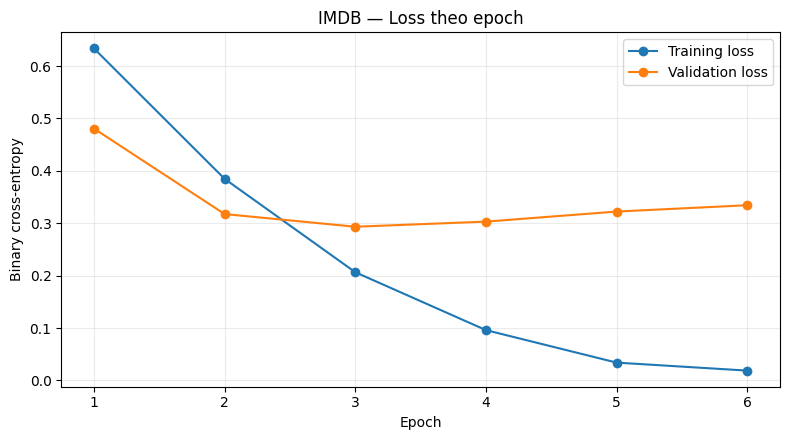

In [34]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)

display(history_df)

plt.figure(figsize=(8, 4.5))
plt.plot(history_df.index, history_df['loss'], marker='o', label='Training loss')
plt.plot(history_df.index, history_df['val_loss'], marker='o', label='Validation loss')
plt.title('IMDB — Loss theo epoch')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

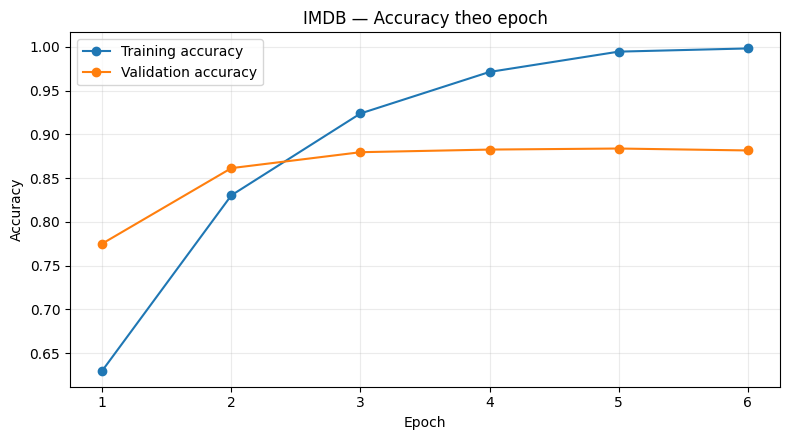

In [35]:
plt.figure(figsize=(8, 4.5))
plt.plot(history_df.index, history_df['accuracy'], marker='o', label='Training accuracy')
plt.plot(history_df.index, history_df['val_accuracy'], marker='o', label='Validation accuracy')
plt.title('IMDB — Accuracy theo epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Đánh giá trên tập test

Tập test chỉ được dùng sau khi hoàn tất thiết kế và huấn luyện. Ngoài Accuracy, ta xem:

- **Precision:** trong các mẫu mô hình dự đoán thuộc lớp đó, bao nhiêu mẫu đúng.
- **Recall:** trong các mẫu thật sự thuộc lớp đó, mô hình tìm ra bao nhiêu.
- **F1-score:** trung bình điều hoà của Precision và Recall.
- **Confusion matrix:** số lượng dự đoán đúng/sai theo từng hướng.

In [36]:
test_loss, test_accuracy = imdb_model.evaluate(test_ds, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')

y_true_imdb = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])
y_prob_imdb = imdb_model.predict(test_ds, verbose=0).ravel()
y_pred_imdb = (y_prob_imdb >= 0.5).astype(int)

print('\nClassification report:')
print(classification_report(
    y_true_imdb,
    y_pred_imdb,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    digits=4,
    zero_division=0,
))


Test loss: 0.3018
Test accuracy: 0.8708



Classification report:
              precision    recall  f1-score   support

    Negative     0.8445    0.9090    0.8756     12500
    Positive     0.9015    0.8326    0.8657     12500

    accuracy                         0.8708     25000
   macro avg     0.8730    0.8708    0.8706     25000
weighted avg     0.8730    0.8708    0.8706     25000



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


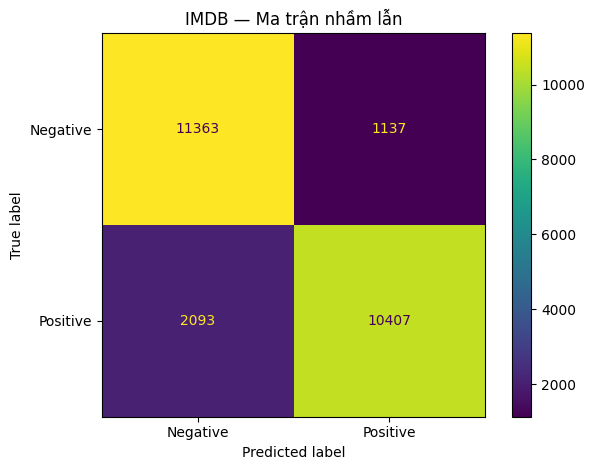

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:
cm_imdb = confusion_matrix(y_true_imdb, y_pred_imdb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_imdb,
    display_labels=['Negative', 'Positive'],
)
disp.plot(values_format='d')
plt.title('IMDB — Ma trận nhầm lẫn')
plt.tight_layout()
plt.show()

<div class="result-box"><b>Cách đọc ma trận:</b> Hai ô trên đường chéo là dự đoán đúng. Ô ngoài đường chéo cho biết review tiêu cực bị đoán thành tích cực và ngược lại. Khi viết báo cáo, cần nêu loại lỗi nào nhiều hơn và giả thuyết nguyên nhân.</div>

## 10. Thử dự đoán câu mới

In [38]:
new_reviews = np.array([
    'This movie was touching, beautifully acted and absolutely worth watching.',
    'The plot was boring, the dialogue was weak and I regret watching it.',
    'The film starts slowly but the ending is surprisingly good.',
])

new_review_ids = vectorizer(tf.constant(new_reviews))
probs = imdb_model.predict(
    new_review_ids,
    batch_size=BATCH_SIZE,
    verbose=0,
).ravel()

pred_table = pd.DataFrame({
    'Review': new_reviews,
    'P(Positive)': probs,
    'Dự đoán': np.where(probs >= 0.5, 'Positive', 'Negative'),
})
display(pred_table)


,Review,P(Positive),Dự đoán
0,"This movie was touching, beautifully acted and...",0.996520,Positive
1,"The plot was boring, the dialogue was weak and...",0.001026,Negative
2,The film starts slowly but the ending is surpr...,0.981114,Positive


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Nhận xét Assignment 1

Điền sau khi chạy chế độ đầy đủ:

- Test Accuracy: **...............**
- Lớp có Recall thấp hơn: **...............**
- Khoảng cách train/validation ở epoch cuối: **...............**
- Dấu hiệu overfitting: **Có / Không**, vì **........................................................**
- Một hạn chế của TextCNN: kernel tích chập chủ yếu học mẫu cục bộ, nên quan hệ rất dài trong review vẫn có thể chưa được biểu diễn đầy đủ.


# PHẦN C — ASSIGNMENT 2: BBC NEWS ARTICLES

## 11. Bài toán đa lớp

Dữ liệu BBC gồm các bài báo thuộc 5 chủ đề:

- `business`
- `entertainment`
- `politics`
- `sport`
- `tech`

Đây là **multiclass classification**: mỗi bài chỉ thuộc một lớp. Ta so sánh hai cách biểu diễn:

1. **TF-IDF:** vector thưa dựa trên mức độ quan trọng của từ/ngữ.
2. **Doc2Vec:** vector dày học biểu diễn cho toàn tài liệu.

Sau đó thử Logistic Regression, Random Forest và XGBoost.

![BBC pipeline](attachment:bbc_pipeline.png)

**Giải thích hình:** TF-IDF và Doc2Vec trả lời hai câu hỏi khác nhau. TF-IDF nhấn mạnh “từ nào đặc trưng cho tài liệu”, còn Doc2Vec cố học một vector liên tục tóm tắt tài liệu. So sánh cả hai giúp đánh giá liệu biểu diễn phức tạp hơn có thực sự tốt hơn trên bộ dữ liệu nhỏ.

## 12. Tải và kiểm tra dữ liệu BBC

In [39]:
# BBC_URL = 'https://storage.googleapis.com/dataset-uploader/bbc/bbc-text.csv'
BBC_URL ='https://huggingface.co/datasets/SetFit/bbc-news/resolve/main/bbc-text.csv'
try:
    bbc_df = pd.read_csv(BBC_URL)
except Exception as download_error:
    print('Không tải được BBC CSV từ Internet:', download_error)
    print('Hãy tải file bbc-text.csv lên phiên làm việc.')
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
        if not csv_files:
            raise ValueError('Chưa có file CSV nào được tải lên.')
        bbc_df = pd.read_csv(csv_files[0])
    except ImportError as exc:
        raise RuntimeError(
            'Môi trường hiện tại không phải Colab. Hãy tải bbc-text.csv về máy '
            'và thay BBC_URL bằng đường dẫn cục bộ.'
        ) from exc

required_columns = {'category', 'text'}
if not required_columns.issubset(bbc_df.columns):
    raise ValueError(f'Dữ liệu thiếu cột bắt buộc: {required_columns - set(bbc_df.columns)}')

print('Kích thước ban đầu:', bbc_df.shape)
display(bbc_df.head())

Kích thước ban đầu: (2225, 2)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


In [40]:
quality_report = pd.DataFrame({
    'Số giá trị thiếu': bbc_df[['category', 'text']].isna().sum(),
    'Số giá trị duy nhất': bbc_df[['category', 'text']].nunique(),
})

display(quality_report)
print('Số dòng trùng hoàn toàn:', bbc_df.duplicated().sum())

bbc_df = (
    bbc_df[['category', 'text']]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

print('Kích thước sau làm sạch cấu trúc:', bbc_df.shape)

,Số giá trị thiếu,Số giá trị duy nhất
category,0,5
text,0,2126


Số dòng trùng hoàn toàn: 99
Kích thước sau làm sạch cấu trúc: (2126, 2)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<div class="why-box"><b>Tại sao kiểm tra thiếu và trùng?</b> Dòng thiếu không thể dùng trực tiếp; dòng trùng có thể làm mô hình “nhìn thấy lại” cùng nội dung ở train và test, khiến kết quả cao giả tạo.</div>

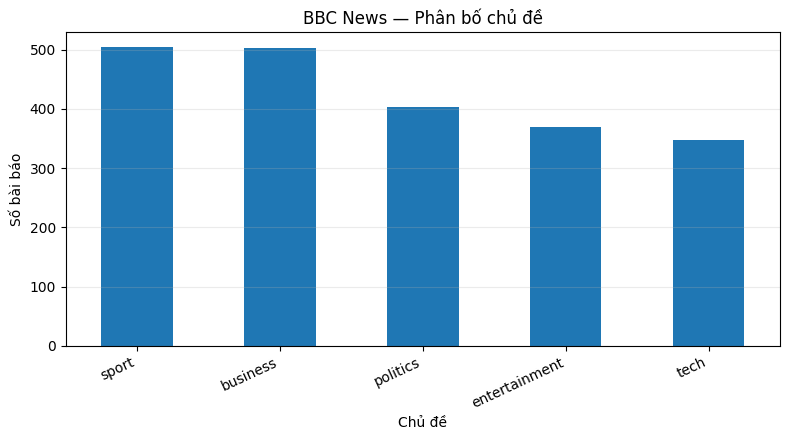

category
sport            504
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [41]:
category_counts = bbc_df['category'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
category_counts.plot(kind='bar')
plt.title('BBC News — Phân bố chủ đề')
plt.xlabel('Chủ đề')
plt.ylabel('Số bài báo')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(category_counts)

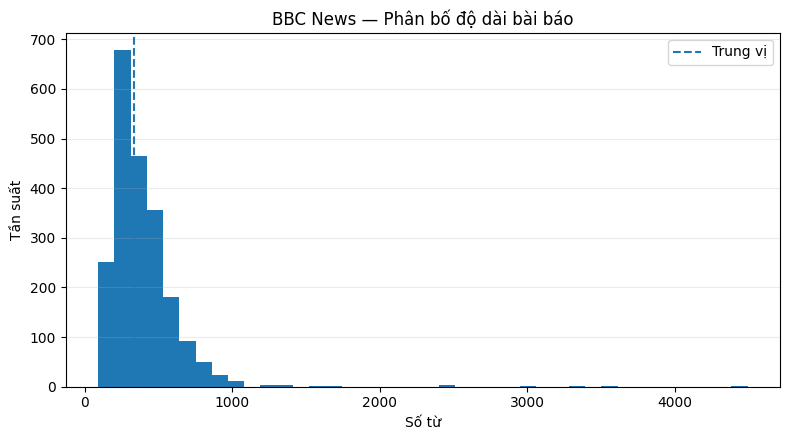

count    2126.000000
mean      390.452023
std       245.118037
min        90.000000
50%       336.500000
75%       479.000000
90%       628.000000
95%       742.750000
max      4492.000000
Name: word_count, dtype: float64


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [42]:
bbc_df['word_count'] = bbc_df['text'].str.split().str.len()

plt.figure(figsize=(8, 4.5))
plt.hist(bbc_df['word_count'], bins=40)
plt.axvline(bbc_df['word_count'].median(), linestyle='--', label='Trung vị')
plt.title('BBC News — Phân bố độ dài bài báo')
plt.xlabel('Số từ')
plt.ylabel('Tần suất')
plt.legend()
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(bbc_df['word_count'].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))

## 13. Làm sạch văn bản BBC

Hàm bên dưới:

1. Viết thường và bỏ dấu Unicode.
2. Tách từ bằng `simple_preprocess`.
3. Bỏ stopword tiếng Anh.
4. Bỏ token quá ngắn.

Notebook **không stemming mặc định** vì từ bị cắt gốc thường khó đọc trên WordCloud và có thể làm mất sắc thái tên riêng/chủ đề. Có thể thử stemming như một thí nghiệm riêng.

<div class="why-box"><b>Lý do phải fit preprocessing chỉ trên train:</b> Các phép “học” như xây vocabulary, IDF hay Doc2Vec không được quan sát test. Hàm làm sạch theo quy tắc cố định thì có thể áp dụng giống nhau cho mọi tập.</div>

In [43]:
STOPWORDS = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    tokens = simple_preprocess(
        str(text),
        deacc=True,     # bỏ dấu Unicode
        min_len=2,
        max_len=30,
    )
    tokens = [token for token in tokens if token not in STOPWORDS]
    return ' '.join(tokens)

bbc_df['clean_text'] = bbc_df['text'].map(clean_text)

example_idx = 2
print('TRƯỚC LÀM SẠCH:\n', bbc_df.loc[example_idx, 'text'][:800])
print('\nSAU LÀM SẠCH:\n', bbc_df.loc[example_idx, 'clean_text'][:800])

TRƯỚC LÀM SẠCH:
 tigers wary of farrell  gamble  leicester say they will not be rushed into making a bid for andy farrell should the great britain rugby league captain decide to switch codes.   we and anybody else involved in the process are still some way away from going to the next stage   tigers boss john wells told bbc radio leicester.  at the moment  there are still a lot of unknowns about andy farrell  not least his medical situation.  whoever does take him on is going to take a big  big gamble.  farrell  who has had persistent knee problems  had an operation on his knee five weeks ago and is expected to be out for another three months. leicester and saracens are believed to head the list of rugby union clubs interested in signing farrell if he decides to move to the 15-man game.  if he does move acr

SAU LÀM SẠCH:
 tigers wary farrell gamble leicester say rushed making bid andy farrell great britain rugby league captain decide switch codes anybody involved process way away going

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 14. WordCloud — trực quan hoá từ nổi bật

WordCloud làm từ xuất hiện nhiều có kích thước lớn hơn. Đây là công cụ **khám phá**, không phải bằng chứng định lượng về khả năng dự đoán.

<div class="warning-box"><b>Cẩn thận khi diễn giải:</b> Tần suất cao không đồng nghĩa với quan hệ nhân quả. WordCloud cũng không thể hiện tốt ngữ cảnh, phủ định hoặc cụm từ dài.</div>

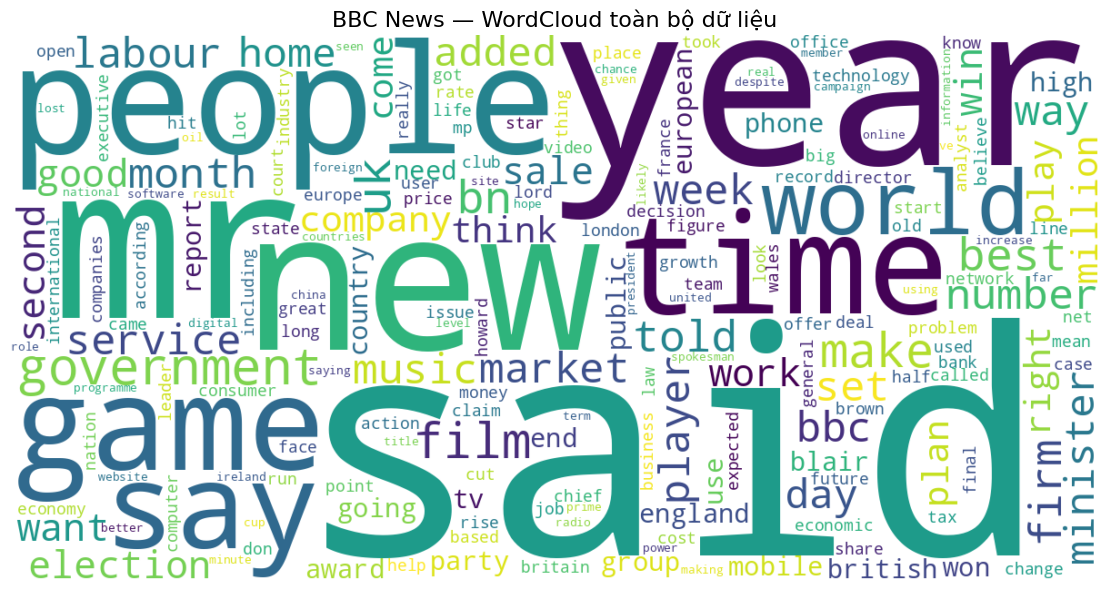

In [44]:
def plot_wordcloud(text, title):
    cloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        collocations=False,
        random_state=SEED,
    ).generate(text)

    plt.figure(figsize=(13, 6))
    plt.imshow(cloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.show()

all_bbc_text = ' '.join(bbc_df['clean_text'])
plot_wordcloud(all_bbc_text, 'BBC News — WordCloud toàn bộ dữ liệu')

In [45]:
# Tạo WordCloud riêng cho từng chủ đề.
for category in sorted(bbc_df['category'].unique()):
    category_text = ' '.join(
        bbc_df.loc[bbc_df['category'] == category, 'clean_text']
    )
    plot_wordcloud(category_text, f'BBC News — Từ nổi bật của chủ đề: {category}')

Output hidden; open in https://colab.research.google.com to view.

### Gợi ý nhận xét WordCloud

- `sport` thường có từ liên quan trận đấu, đội tuyển, cầu thủ hoặc giải đấu.
- `business` thường chứa từ liên quan công ty, thị trường, tăng trưởng, giá và kinh tế.
- `tech` thường có từ về phần mềm, internet, thiết bị hoặc người dùng.
- Các từ xuất hiện ở nhiều lớp ít có giá trị phân biệt hơn từ đặc trưng riêng cho một lớp.

Hãy thay nhận xét tổng quát trên bằng từ cụ thể quan sát được sau khi chạy notebook.

## 15. Chia development/final test có phân tầng

Ta giữ riêng **final test** ngay từ đầu. Tập này không được dùng để:

- chọn mô hình;
- điều chỉnh hyperparameter;
- xây vocabulary hoặc IDF;
- huấn luyện Doc2Vec;
- đánh giá lặp lại.

Phần còn lại gọi là **development set**. Development set tiếp tục được chia thành train/validation để minh hoạ từng mô hình, đồng thời được dùng cho repeated holdout ở mục 20b.

`stratify=y` giúp tỷ lệ 5 lớp trong các tập gần giống dữ liệu gốc.

<div class="why-box"><b>Lý do giữ final test:</b> Nếu vừa dùng test để chọn mô hình vừa báo cáo điểm trên chính test đó, kết quả sẽ lạc quan. Final test chỉ được mở đúng một lần sau khi đã chọn mô hình bằng development set.</div>


In [46]:
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(bbc_df['category'])
X_all = bbc_df['clean_text'].to_numpy()


# ==================================================
# BƯỚC 1: GIỮ RIÊNG FINAL TEST
# ==================================================
X_dev, X_final_test_text, y_dev, y_final_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all,
)


# ==================================================
# BƯỚC 2: CHIA DEVELOPMENT SET THÀNH TRAIN/VALIDATION
# ==================================================
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=SEED,
    stratify=y_dev,
)


print('Classes:', list(label_encoder.classes_))
print(
    'Train:', len(X_train_text),
    '| Validation:', len(X_test_text),
    '| Final test:', len(X_final_test_text),
)


split_distribution = pd.DataFrame({
    'Train': pd.Series(
        label_encoder.inverse_transform(y_train)
    ).value_counts(normalize=True),

    'Validation': pd.Series(
        label_encoder.inverse_transform(y_test)
    ).value_counts(normalize=True),

    'Final test': pd.Series(
        label_encoder.inverse_transform(y_final_test)
    ).value_counts(normalize=True),
}).fillna(0)


display(split_distribution)


Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']
Train: 1360 | Validation: 340 | Final test: 426


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Train,Validation,Final test
business,0.236765,0.235294,0.237089
entertainment,0.173529,0.173529,0.173709
politics,0.189706,0.188235,0.190141
sport,0.236765,0.238235,0.237089
tech,0.163235,0.164706,0.161972


## 16. Mô hình baseline: TF-IDF + Logistic Regression

TF-IDF giảm trọng số của từ xuất hiện ở quá nhiều tài liệu và tăng trọng số cho từ đặc trưng.

Với `sublinear_tf=True`, tần suất từ được biến đổi:

$$
\mathrm{tf}_{\log}(t,d)=
\begin{cases}
1+\log(\mathrm{count}(t,d)), & \mathrm{count}(t,d)>0 \\
0, & \text{ngược lại}
\end{cases}
$$

Với `smooth_idf=True` mặc định của scikit-learn:

$$
\mathrm{idf}(t)
=
\log\left(
\frac{1+N}{1+\mathrm{df}(t)}
\right)+1
$$

Do đó:

$$
\mathrm{tfidf}(t,d)
=
\mathrm{tf}_{\log}(t,d)\times\mathrm{idf}(t)
$$

Ta dùng cả unigram và bigram để mô hình có thể học cụm hai từ. Logistic Regression là baseline mạnh cho vector thưa, nhiều chiều.

### Cross-validation

Tập train được chia thành nhiều fold. Mỗi lượt dùng một fold để validation và phần còn lại để train. TF-IDF nằm **bên trong Pipeline**, vì vậy vocabulary và IDF được fit lại riêng trong từng fold, tránh data leakage.


In [47]:
tfidf_lr = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=20_000 if QUICK_MODE else 50_000,
        sublinear_tf=True,
    )),
    ('classifier', LogisticRegression(
        max_iter=1_500,
        class_weight='balanced',
        random_state=SEED,
    )),
])

cv = StratifiedKFold(
    n_splits=3 if QUICK_MODE else 5,
    shuffle=True,
    random_state=SEED,
)

cv_scores = cross_val_score(
    tfidf_lr,
    X_train_text,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
)

print('TF-IDF + Logistic Regression CV scores:', np.round(cv_scores, 4))
print(f'CV mean: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

TF-IDF + Logistic Regression CV scores: [0.9853 0.9779 0.9669 0.9743 0.9743]
CV mean: 0.9757 ± 0.0060


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<div class="result-box"><b>Cách đọc CV:</b> Trung bình cho biết hiệu năng điển hình; độ lệch chuẩn nhỏ cho thấy kết quả ít phụ thuộc vào cách chia fold. CV ở đây chỉ dùng trên tập train để kiểm tra baseline. Việc chọn mô hình cuối cùng sẽ dựa trên repeated holdout của development set ở mục 20b; final test chưa được sử dụng.</div>


In [48]:
def fit_and_evaluate(
    name,
    estimator,
    X_train,
    y_train,
    X_validation,
    y_validation,
):
    start = time.perf_counter()

    estimator.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start

    predictions = estimator.predict(X_validation)

    result = {
        'Model': name,
        'Accuracy': accuracy_score(
            y_validation,
            predictions,
        ),
        'Macro F1': f1_score(
            y_validation,
            predictions,
            average='macro',
            zero_division=0,
        ),
        'Train time (s)': train_seconds,
    }

    return result, predictions, estimator


# Các kết quả dưới đây là kết quả trên VALIDATION,
# chỉ dùng để minh hoạ và trực quan hoá.
results = []
predictions_by_model = {}
models_by_name = {}


result, pred, fitted_tfidf_lr = fit_and_evaluate(
    'TF-IDF + Logistic Regression',
    tfidf_lr,
    X_train_text,
    y_train,
    X_test_text,
    y_test,
)

results.append(result)
predictions_by_model[result['Model']] = pred
models_by_name[result['Model']] = fitted_tfidf_lr

print(result)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


{'Model': 'TF-IDF + Logistic Regression', 'Accuracy': 0.9764705882352941, 'Macro F1': 0.9754726536560426, 'Train time (s)': 2.6265256909999835}


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 17. Biểu diễn Doc2Vec

Doc2Vec học một vector dày cho mỗi tài liệu. Ở phần minh hoạ train/validation, quy trình đúng là:

1. Tách train/validation trước.
2. Xây vocabulary và huấn luyện Doc2Vec **chỉ trên train**.
3. Dùng vector đã học cho tài liệu train.
4. Dùng `infer_vector()` để suy ra vector cho tài liệu validation.

Final test vẫn được giữ riêng và chưa xuất hiện trong bước này.

<div class="warning-box"><b>Data leakage thường gặp:</b> Huấn luyện Doc2Vec trên toàn bộ dữ liệu rồi mới chia tập làm cho vectorizer đã quan sát văn bản cần đánh giá. Dù không dùng nhãn, đây vẫn là thông tin ngoài train và có thể làm kết quả lạc quan.</div>


In [49]:
train_tokens = [
    text.split()
    for text in X_train_text
]

validation_tokens = [
    text.split()
    for text in X_test_text
]


tagged_train = [
    TaggedDocument(
        words=tokens,
        tags=[doc_id],
    )
    for doc_id, tokens
    in enumerate(train_tokens)
]


DOC_VECTOR_SIZE = 100
DOC2VEC_EPOCHS = 18 if QUICK_MODE else 40
INFER_EPOCHS = 15 if QUICK_MODE else 30


# Dùng toàn bộ CPU Colab cho Doc2Vec; hashfxn ổn định vẫn giữ seed nhất quán.
doc2vec_model = Doc2Vec(
    vector_size=DOC_VECTOR_SIZE,
    window=5,
    min_count=2,
    workers=DOC2VEC_WORKERS,
    dm=1,
    negative=5,
    seed=SEED,
    epochs=DOC2VEC_EPOCHS,
    hashfxn=stable_hash,
)


doc2vec_model.build_vocab(tagged_train)

doc2vec_model.train(
    tagged_train,
    total_examples=doc2vec_model.corpus_count,
    epochs=doc2vec_model.epochs,
)


X_train_d2v = np.vstack([
    doc2vec_model.dv[doc_id]
    for doc_id in range(len(tagged_train))
])


# Suy luận vector validation.
# Mỗi tài liệu có seed khác nhau nhưng vẫn lặp lại được giữa các phiên chạy.
validation_vectors = []

for doc_idx, tokens in enumerate(validation_tokens):
    doc2vec_model.random.seed(SEED + doc_idx)

    validation_vectors.append(
        doc2vec_model.infer_vector(
            tokens,
            epochs=INFER_EPOCHS,
        )
    )


X_test_d2v = np.vstack(validation_vectors)


print('Train Doc2Vec shape:', X_train_d2v.shape)
print('Validation Doc2Vec shape:', X_test_d2v.shape)


Train Doc2Vec shape: (1360, 100)
Validation Doc2Vec shape: (340, 100)


## 18. Trực quan hoá embedding Doc2Vec bằng PCA

Doc2Vec tạo vector 100 chiều, con người không thể nhìn trực tiếp. PCA chiếu xuống 2 chiều để quan sát xu hướng phân cụm.

<div class="warning-box"><b>Không diễn giải quá mức:</b> PCA làm mất thông tin khi giảm từ 100 xuống 2 chiều. Các cụm chồng lên nhau trên hình không nhất thiết có nghĩa mô hình phân lớp kém trong không gian gốc.</div>

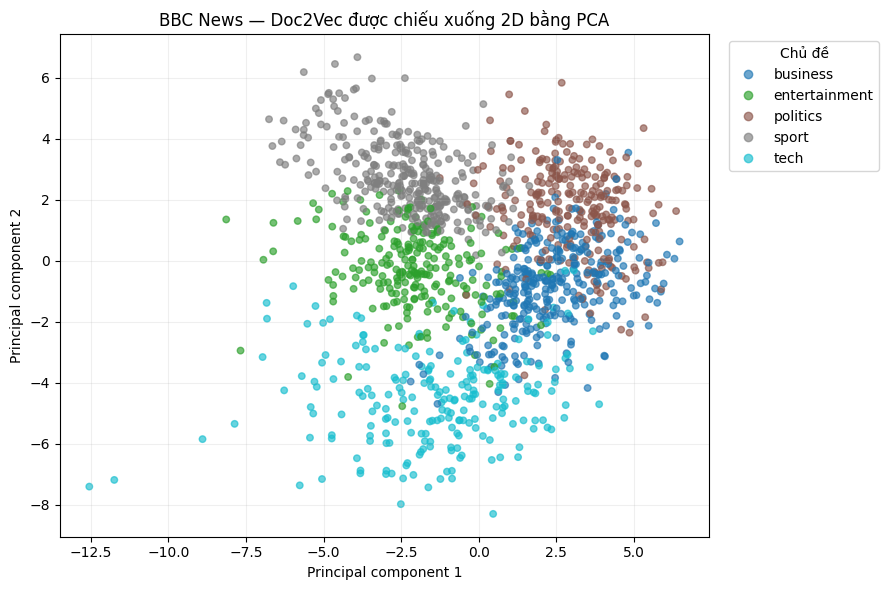

Tổng phương sai được giữ bởi 2 thành phần: 0.20721194


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [50]:
pca = PCA(n_components=2, random_state=SEED)
train_d2v_2d = pca.fit_transform(X_train_d2v)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    train_d2v_2d[:, 0],
    train_d2v_2d[:, 1],
    c=y_train,
    cmap='tab10',
    alpha=0.65,
    s=22,
)
handles, _ = scatter.legend_elements()
plt.legend(handles, label_encoder.classes_, title='Chủ đề', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title('BBC News — Doc2Vec được chiếu xuống 2D bằng PCA')
plt.xlabel('Principal component 1')
plt.ylabel('Principal component 2')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print('Tổng phương sai được giữ bởi 2 thành phần:', pca.explained_variance_ratio_.sum())

## 19. Huấn luyện ba bộ phân lớp trên Doc2Vec

- **Logistic Regression:** ranh giới tuyến tính; baseline ổn định.
- **Random Forest:** tập hợp nhiều cây quyết định; học quan hệ phi tuyến nhưng có thể không lý tưởng trong không gian vector dày.
- **XGBoost:** boosting tuần tự; dùng `device='cuda'` khi GPU khả dụng và tự fallback CPU nếu runtime không hỗ trợ.

<div class="why-box"><b>Lý do so sánh nhiều bộ phân lớp:</b> Chất lượng không chỉ phụ thuộc biểu diễn văn bản. Cùng một vector đầu vào có thể phù hợp với thuật toán này hơn thuật toán khác.</div>

In [51]:
NUM_CLASSES = len(label_encoder.classes_)


doc2vec_classifiers = {
    'Doc2Vec + Logistic Regression': LogisticRegression(
        max_iter=1_500,
        class_weight='balanced',
        random_state=SEED,
    ),

    'Doc2Vec + Random Forest': RandomForestClassifier(
        n_estimators=160 if QUICK_MODE else 400,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=CPU_WORKERS,
    ),

    'Doc2Vec + XGBoost': XGBClassifier(
        n_estimators=140 if QUICK_MODE else 350,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        objective='multi:softprob',
        num_class=NUM_CLASSES,
        eval_metric='mlogloss',
        tree_method='hist',
        device=XGB_DEVICE,
        random_state=SEED,
        n_jobs=CPU_WORKERS,
    ),
}


for name, classifier in doc2vec_classifiers.items():

    result, pred, fitted_model = fit_and_evaluate(
        name,
        classifier,
        X_train_d2v,
        y_train,
        X_test_d2v,
        y_test,
    )

    results.append(result)
    predictions_by_model[name] = pred
    models_by_name[name] = fitted_model

    print(result)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


{'Model': 'Doc2Vec + Logistic Regression', 'Accuracy': 0.9235294117647059, 'Macro F1': 0.9205238784081964, 'Train time (s)': 0.06912875900002291}


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


{'Model': 'Doc2Vec + Random Forest', 'Accuracy': 0.9382352941176471, 'Macro F1': 0.9345885331055033, 'Train time (s)': 6.429710174999968}


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


{'Model': 'Doc2Vec + XGBoost', 'Accuracy': 0.9058823529411765, 'Macro F1': 0.9028546984274964, 'Train time (s)': 2.0654587090000405}


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:553: UserWarning: [18:02:39] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 20. So sánh sơ bộ trên validation set

Ta dùng cả **Accuracy** và **Macro-F1**:

- Accuracy coi mỗi mẫu có trọng số như nhau.
- Macro-F1 tính F1 riêng từng lớp rồi lấy trung bình, vì vậy lớp ít mẫu không bị “che” bởi lớp nhiều mẫu.

Bảng và biểu đồ ở mục này chỉ là so sánh **sơ bộ trên một validation split**. Không dùng bảng này để công bố mô hình tốt nhất. Quyết định cuối được đưa ra ở mục 20b bằng nhiều lần chia development set.


In [52]:
results_df = (
    pd.DataFrame(results)
    .sort_values(['Macro F1', 'Accuracy'], ascending=False)
    .reset_index(drop=True)
)

display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Macro F1': '{:.4f}',
    'Train time (s)': '{:.2f}',
}))

,Model,Accuracy,Macro F1,Train time (s)
0,TF-IDF + Logistic Regression,0.9765,0.9755,2.63
1,Doc2Vec + Random Forest,0.9382,0.9346,6.43
2,Doc2Vec + Logistic Regression,0.9235,0.9205,0.07
3,Doc2Vec + XGBoost,0.9059,0.9029,2.07


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


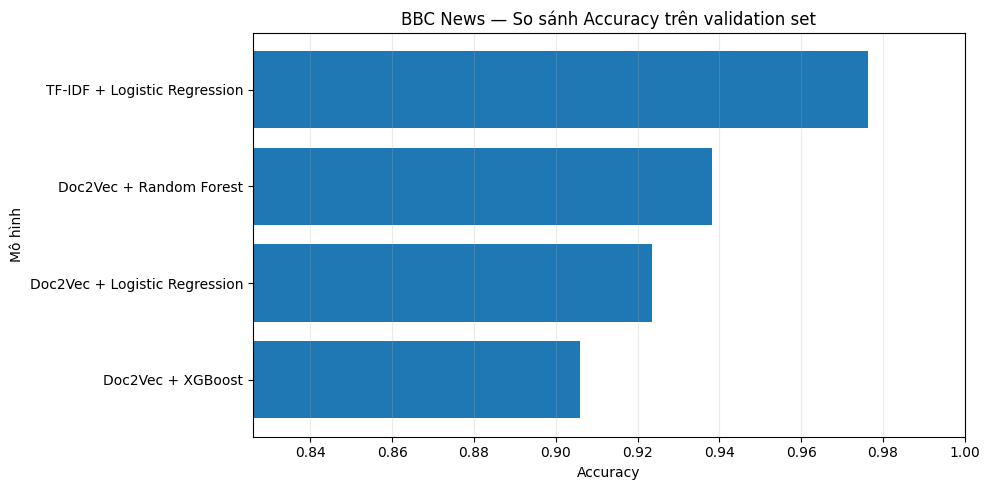

In [53]:
plot_df = results_df.sort_values('Accuracy')

plt.figure(figsize=(10, 5))
plt.barh(plot_df['Model'], plot_df['Accuracy'])
plt.xlim(
    max(0, plot_df['Accuracy'].min() - 0.08),
    1.0,
)
plt.title(
    'BBC News — So sánh Accuracy trên validation set'
)
plt.xlabel('Accuracy')
plt.ylabel('Mô hình')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()


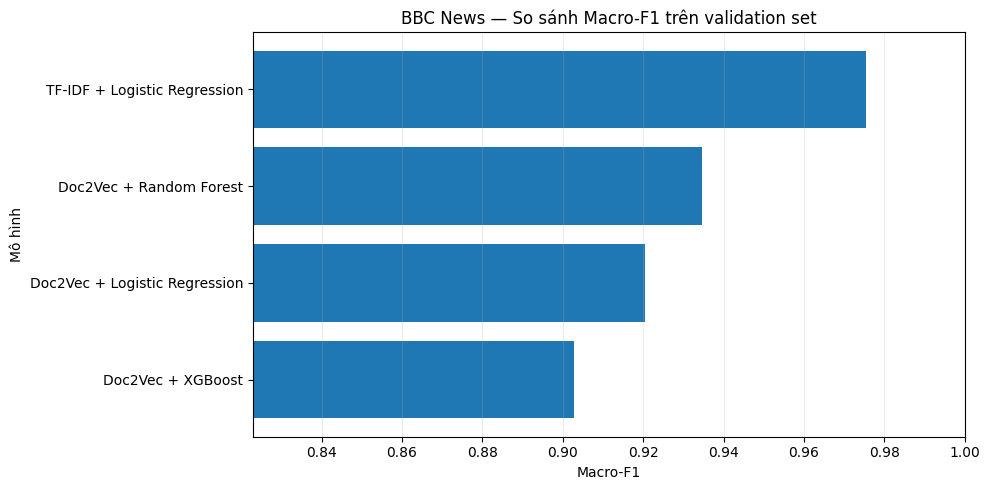

In [54]:
plot_df = results_df.sort_values('Macro F1')

plt.figure(figsize=(10, 5))
plt.barh(plot_df['Model'], plot_df['Macro F1'])
plt.xlim(
    max(0, plot_df['Macro F1'].min() - 0.08),
    1.0,
)
plt.title(
    'BBC News — So sánh Macro-F1 trên validation set'
)
plt.xlabel('Macro-F1')
plt.ylabel('Mô hình')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()


## 20b. Kiểm tra độ ổn định trên development set

Một lần chia train/validation có thể khiến ta kết luận nhầm mô hình nào tốt nhất. Với Doc2Vec, kết quả còn phụ thuộc vào quá trình huấn luyện và suy luận vector.

Ở đây, ta lặp lại toàn bộ quy trình trên **development set**:

1. Chia development thành train/validation theo một seed.
2. Fit TF-IDF hoặc Doc2Vec chỉ trên train của lần lặp đó.
3. Đánh giá classifier trên validation tương ứng.
4. Lặp lại với seed khác.
5. Chọn mô hình theo **mean Macro-F1**.

Final test hoàn toàn không tham gia quy trình này.

<div class="why-box"><b>Vì sao phải huấn luyện lại Doc2Vec ở mỗi lần lặp?</b> Nếu tái sử dụng vector đã học từ lần chia trước, biểu diễn có thể đã quan sát văn bản của validation mới. Huấn luyện lại từ đầu giữ ranh giới train/validation đúng trong từng lần lặp.</div>

<div class="note-box"><b>QUICK_MODE:</b> Chạy 2 lần lặp để kiểm tra lỗi và luồng thực thi. Với báo cáo chính thức, dùng FULL mode (3 lần mặc định). Có thể tăng lên 5 nếu thời gian Colab cho phép.</div>


In [55]:
# ==================================================
# 20b — ĐÁNH GIÁ ĐỘ ỔN ĐỊNH TRÊN DEVELOPMENT SET
# ==================================================

N_REPEATS = 2 if QUICK_MODE else 3

REPEAT_D2V_EPOCHS = (
    8 if QUICK_MODE else DOC2VEC_EPOCHS
)

REPEAT_VECTOR_SIZE = (
    60 if QUICK_MODE else DOC_VECTOR_SIZE
)

REPEAT_RF_TREES = (
    80 if QUICK_MODE else 400
)

REPEAT_XGB_TREES = (
    80 if QUICK_MODE else 350
)


def build_doc2vec_vectors(
    train_text,
    evaluation_text,
    *,
    seed,
    vector_size,
    train_epochs,
    infer_epochs,
):
    """
    Huấn luyện Doc2Vec chỉ trên train_text.

    evaluation_text không tham gia build_vocab hoặc train;
    vector đánh giá chỉ được tạo bằng infer_vector().
    """

    train_tokens_local = [
        text.split()
        for text in train_text
    ]

    evaluation_tokens = [
        text.split()
        for text in evaluation_text
    ]


    tagged_train_local = [
        TaggedDocument(
            words=tokens,
            tags=[doc_id],
        )
        for doc_id, tokens
        in enumerate(train_tokens_local)
    ]


    model = Doc2Vec(
        vector_size=vector_size,
        window=5,
        min_count=2,
        workers=DOC2VEC_WORKERS,
        dm=1,
        negative=5,
        seed=seed,
        epochs=train_epochs,
        hashfxn=stable_hash,
    )


    model.build_vocab(tagged_train_local)

    model.train(
        tagged_train_local,
        total_examples=model.corpus_count,
        epochs=model.epochs,
    )


    train_vectors_local = np.vstack([
        model.dv[doc_id]
        for doc_id in range(
            len(tagged_train_local)
        )
    ])


    evaluation_vectors = []

    for doc_idx, tokens in enumerate(
        evaluation_tokens
    ):
        model.random.seed(seed + doc_idx)

        evaluation_vectors.append(
            model.infer_vector(
                tokens,
                epochs=infer_epochs,
            )
        )


    return (
        train_vectors_local,
        np.vstack(evaluation_vectors),
        model,
    )


repeat_records = []
stability_start = time.perf_counter()


for repeat_idx in range(N_REPEATS):

    repeat_start = time.perf_counter()
    repeat_seed = SEED + repeat_idx


    (
        Xr_train_text,
        Xr_validation_text,
        yr_train,
        yr_validation,
    ) = train_test_split(
        X_dev,
        y_dev,
        test_size=0.20,
        random_state=repeat_seed,
        stratify=y_dev,
    )


    # ==============================================
    # TF-IDF + LOGISTIC REGRESSION
    # ==============================================
    tfidf_repeat = Pipeline([
        (
            'tfidf',
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                max_features=(
                    20_000
                    if QUICK_MODE
                    else 50_000
                ),
                sublinear_tf=True,
            ),
        ),

        (
            'classifier',
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=repeat_seed,
            ),
        ),
    ])


    tfidf_repeat.fit(
        Xr_train_text,
        yr_train,
    )

    tfidf_predictions = tfidf_repeat.predict(
        Xr_validation_text
    )


    repeat_records.append({
        'Model': 'TF-IDF + Logistic Regression',
        'Repeat': repeat_idx + 1,

        'Accuracy': accuracy_score(
            yr_validation,
            tfidf_predictions,
        ),

        'Macro F1': f1_score(
            yr_validation,
            tfidf_predictions,
            average='macro',
            zero_division=0,
        ),
    })


    # ==============================================
    # DOC2VEC
    # ==============================================
    (
        Xr_train_d2v,
        Xr_validation_d2v,
        _,
    ) = build_doc2vec_vectors(
        Xr_train_text,
        Xr_validation_text,
        seed=repeat_seed,
        vector_size=REPEAT_VECTOR_SIZE,
        train_epochs=REPEAT_D2V_EPOCHS,
        infer_epochs=REPEAT_D2V_EPOCHS,
    )


    repeat_classifiers = {
        'Doc2Vec + Logistic Regression':
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=repeat_seed,
            ),

        'Doc2Vec + Random Forest':
            RandomForestClassifier(
                n_estimators=REPEAT_RF_TREES,
                class_weight='balanced',
                random_state=repeat_seed,
                n_jobs=CPU_WORKERS,
            ),

        'Doc2Vec + XGBoost':
            XGBClassifier(
                n_estimators=REPEAT_XGB_TREES,
                max_depth=6,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                objective='multi:softprob',
                num_class=NUM_CLASSES,
                eval_metric='mlogloss',
                tree_method='hist',
                device=XGB_DEVICE,
                random_state=repeat_seed,
                n_jobs=CPU_WORKERS,
            ),
    }


    for model_name, classifier in (
        repeat_classifiers.items()
    ):

        classifier.fit(
            Xr_train_d2v,
            yr_train,
        )

        predictions = classifier.predict(
            Xr_validation_d2v
        )


        repeat_records.append({
            'Model': model_name,
            'Repeat': repeat_idx + 1,

            'Accuracy': accuracy_score(
                yr_validation,
                predictions,
            ),

            'Macro F1': f1_score(
                yr_validation,
                predictions,
                average='macro',
                zero_division=0,
            ),
        })


    repeat_seconds = (
        time.perf_counter()
        - repeat_start
    )

    print(
        f'Đã xong lần '
        f'{repeat_idx + 1}/{N_REPEATS} '
        f'(seed={repeat_seed}) '
        f'trong {repeat_seconds:.1f} giây.'
    )


repeat_df = pd.DataFrame(repeat_records)


stability_summary = (
    repeat_df
    .groupby('Model')[
        ['Accuracy', 'Macro F1']
    ]
    .agg(['mean', 'std'])
    .sort_values(
        ('Macro F1', 'mean'),
        ascending=False,
    )
)


selected_model_name = (
    stability_summary.index[0]
)


stability_seconds = (
    time.perf_counter()
    - stability_start
)


print(
    f'\nTổng thời gian mục 20b: '
    f'{stability_seconds:.1f} giây.'
)

print(
    'Mô hình được chọn theo '
    'mean Macro-F1:',
    selected_model_name,
)


display(
    stability_summary.style.format('{:.4f}')
)


if QUICK_MODE:
    print(
        '\nLƯU Ý: QUICK_MODE chỉ chạy 2 lần lặp. '
        'Giá trị std chỉ dùng để kiểm tra nhanh, '
        'không dùng làm kết luận thống kê cuối cùng.'
    )


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future ver

Đã xong lần 1/3 (seed=42) trong 46.9 giây.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.

Đã xong lần 2/3 (seed=43) trong 47.1 giây.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.

Đã xong lần 3/3 (seed=44) trong 45.0 giây.

Tổng thời gian mục 20b: 139.0 giây.
Mô hình được chọn theo mean Macro-F1: TF-IDF + Logistic Regression


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 21. Refit mô hình được chọn và đánh giá final test

`selected_model_name` được chọn hoàn toàn từ kết quả repeated holdout trên development set.

Tiếp theo:

1. Fit lại mô hình được chọn trên **toàn bộ development set**.
2. Mở final test đúng một lần.
3. Báo cáo Accuracy, Macro-F1, classification report và confusion matrix.

<div class="warning-box"><b>Không quay lại điều chỉnh mô hình theo final test:</b> Nếu thay hyperparameter sau khi xem final test, tập này không còn là đánh giá độc lập. Khi đó cần một test set mới.</div>


In [56]:
# ==================================================
# CHỌN, REFIT VÀ ĐÁNH GIÁ MÔ HÌNH CUỐI
# ==================================================

best_model_name = selected_model_name
best_doc2vec_model = None


if best_model_name == 'TF-IDF + Logistic Regression':

    best_model = Pipeline([
        (
            'tfidf',
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                max_features=(
                    20_000
                    if QUICK_MODE
                    else 50_000
                ),
                sublinear_tf=True,
            ),
        ),

        (
            'classifier',
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=SEED,
            ),
        ),
    ])


    # Refit trên toàn bộ development set.
    best_model.fit(
        X_dev,
        y_dev,
    )


    # Final test chỉ được dùng sau khi mô hình đã được chọn.
    best_predictions = best_model.predict(
        X_final_test_text
    )


else:

    (
        X_dev_d2v,
        X_final_test_d2v,
        best_doc2vec_model,
    ) = build_doc2vec_vectors(
        X_dev,
        X_final_test_text,
        seed=SEED,
        vector_size=DOC_VECTOR_SIZE,
        train_epochs=DOC2VEC_EPOCHS,
        infer_epochs=INFER_EPOCHS,
    )


    final_doc2vec_classifiers = {
        'Doc2Vec + Logistic Regression':
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=SEED,
            ),

        'Doc2Vec + Random Forest':
            RandomForestClassifier(
                n_estimators=(
                    160
                    if QUICK_MODE
                    else 400
                ),
                class_weight='balanced',
                random_state=SEED,
                n_jobs=CPU_WORKERS,
            ),

        'Doc2Vec + XGBoost':
            XGBClassifier(
                n_estimators=(
                    140
                    if QUICK_MODE
                    else 350
                ),
                max_depth=6,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                objective='multi:softprob',
                num_class=NUM_CLASSES,
                eval_metric='mlogloss',
                tree_method='hist',
                device=XGB_DEVICE,
                random_state=SEED,
                n_jobs=CPU_WORKERS,
            ),
    }


    best_model = final_doc2vec_classifiers[
        best_model_name
    ]


    best_model.fit(
        X_dev_d2v,
        y_dev,
    )


    best_predictions = best_model.predict(
        X_final_test_d2v
    )


final_accuracy = accuracy_score(
    y_final_test,
    best_predictions,
)

final_macro_f1 = f1_score(
    y_final_test,
    best_predictions,
    average='macro',
    zero_division=0,
)


print('Mô hình được chọn:', best_model_name)
print(f'FINAL TEST Accuracy: {final_accuracy:.4f}')
print(f'FINAL TEST Macro-F1: {final_macro_f1:.4f}')


print('\nClassification report trên FINAL TEST:')
print(classification_report(
    y_final_test,
    best_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0,
))


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Mô hình được chọn: TF-IDF + Logistic Regression
FINAL TEST Accuracy: 0.9789
FINAL TEST Macro-F1: 0.9785

Classification report trên FINAL TEST:
               precision    recall  f1-score   support

     business     0.9515    0.9703    0.9608       101
entertainment     0.9730    0.9730    0.9730        74
     politics     1.0000    0.9753    0.9875        81
        sport     1.0000    1.0000    1.0000       101
         tech     0.9710    0.9710    0.9710        69

     accuracy                         0.9789       426
    macro avg     0.9791    0.9779    0.9785       426
 weighted avg     0.9791    0.9789    0.9789       426



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


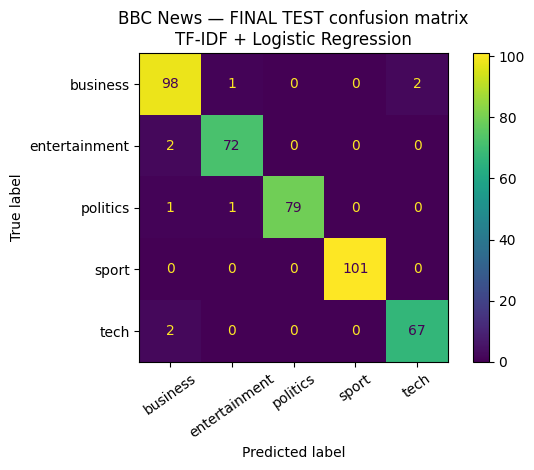

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [57]:
cm_bbc = confusion_matrix(
    y_final_test,
    best_predictions,
    labels=np.arange(NUM_CLASSES),
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bbc,
    display_labels=label_encoder.classes_,
)


disp.plot(
    values_format='d',
    xticks_rotation=35,
)


plt.title(
    'BBC News — FINAL TEST confusion matrix\n'
    f'{best_model_name}'
)

plt.tight_layout()
plt.show()


<div class="result-box"><b>Cách viết nhận xét:</b> Tìm hai lớp bị nhầm nhiều nhất, xem các từ/chủ đề giao nhau và giải thích. Ví dụ, bài về doanh nghiệp công nghệ có thể chứa từ của cả `business` và `tech`.</div>

## 22. Xem các dự đoán sai trên final test

Phân tích lỗi giúp tìm ra vấn đề mà một con số tổng hợp không thể hiện được. Chỉ quan sát và mô tả lỗi; không tiếp tục tối ưu mô hình dựa trên final test.


In [58]:
error_indices = np.where(
    best_predictions != y_final_test
)[0]


if len(error_indices) == 0:

    print(
        'Không có dự đoán sai '
        'trên FINAL TEST hiện tại.'
    )

else:

    sample_error_indices = error_indices[:10]
    error_rows = []


    for idx in sample_error_indices:

        actual_label = label_encoder.inverse_transform(
            [y_final_test[idx]]
        )[0]

        predicted_label = label_encoder.inverse_transform(
            [best_predictions[idx]]
        )[0]


        error_rows.append({
            'Nhãn thật': actual_label,
            'Dự đoán': predicted_label,
            'Văn bản rút gọn':
                X_final_test_text[idx][:350] + '...',
        })


    display(pd.DataFrame(error_rows))


,Nhãn thật,Dự đoán,Văn bản rút gọn
0,business,tech,id theft surge hits consumers quarter million ...
1,business,entertainment,mcdonald sponsor mtv mcdonald world largest re...
2,tech,business,argonaut founder rebuilds empire jez san man a...
3,entertainment,business,uk national gallery pink national gallery home...
4,tech,business,games maker fights survival britain largest in...
5,politics,business,eu fraud clampdown urged eu member states fail...
6,business,tech,card fraudsters targeting web new safeguards c...
7,entertainment,business,german music zombie state german music busines...
8,politics,entertainment,mp shock long lost daughter labour mp stephen ...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 23. Dự đoán bài báo mới

Để dự đoán đúng pipeline cuối cùng:

- Với TF-IDF: đưa văn bản đã làm sạch vào `best_model`, trong đó TF-IDF và classifier đã được fit trên toàn bộ development set.
- Với Doc2Vec: dùng chính `best_doc2vec_model` đã fit trên development set để `infer_vector()`, sau đó gọi classifier cuối.

Số epoch inference được giữ giống bước đánh giá final test.


In [59]:
new_articles = [
    (
        'The company announced higher quarterly '
        'profits after strong online sales and '
        'lower costs.'
    ),

    (
        'The team scored twice in the final '
        'minutes to win the championship match.'
    ),

    (
        'A new mobile software platform promises '
        'better privacy and faster internet services.'
    ),
]


clean_new_articles = [
    clean_text(text)
    for text in new_articles
]


if best_model_name.startswith('TF-IDF'):

    new_pred_ids = best_model.predict(
        clean_new_articles
    )


else:

    new_vectors = []


    for doc_idx, text in enumerate(
        clean_new_articles
    ):

        best_doc2vec_model.random.seed(
            SEED + doc_idx
        )

        new_vectors.append(
            best_doc2vec_model.infer_vector(
                text.split(),
                epochs=INFER_EPOCHS,
            )
        )


    new_pred_ids = best_model.predict(
        np.vstack(new_vectors)
    )


new_pred_labels = label_encoder.inverse_transform(
    new_pred_ids
)


display(pd.DataFrame({
    'Bài báo mới': new_articles,
    'Dự đoán chủ đề': new_pred_labels,
}))


,Bài báo mới,Dự đoán chủ đề
0,The company announced higher quarterly profits...,business
1,The team scored twice in the final minutes to ...,sport
2,A new mobile software platform promises better...,tech


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# PHẦN E — MỞ RỘNG: KIẾN TRÚC KHÁC, PHÂN TÍCH SÂU HƠN VÀ KIỂM ĐỊNH THỐNG KÊ

<div class="note-box"><b>Vị trí trong notebook:</b> Phần này chạy <b>sau</b> khi đã có đầy đủ <code>imdb_model</code>, <code>vectorizer</code>, <code>train_ds/val_ds/test_ds</code> (Assignment 1) và <code>X_train_text/y_train</code>, <code>results</code>, <code>repeat_df</code>, <code>best_model_name</code>, <code>best_predictions</code> (Assignment 2), nên có thể tái sử dụng trực tiếp mà không cần load lại dữ liệu.</div>

<div class="warning-box"><b>Về thời gian chạy:</b> Phần này train thêm 2 mô hình RNN (BiLSTM, BiGRU) và 1 mô hình SVM, nên sẽ tốn thêm vài phút trên GPU T4. Nếu chỉ muốn kiểm tra luồng code, có thể tạm giảm <code>RECURRENT_EPOCHS</code> ở mục E1.</div>

## E1. So sánh kiến trúc cho IMDB: Conv1D vs BiLSTM vs BiGRU

Conv1D (TextCNN) ở Phần B học tốt các cụm từ cục bộ (n-gram) và tận dụng GPU rất hiệu quả, nhưng
không thực sự "đọc" câu theo thứ tự. RNN hai chiều (Bidirectional LSTM/GRU) xử lý chuỗi tuần tự,
có thể nắm ngữ cảnh xa hơn, đổi lại tốc độ train chậm hơn vì phải tính tuần tự qua từng token.

Ta giữ nguyên toàn bộ tiền xử lý (`vectorizer`, `train_ds`, `val_ds`, `test_ds`) và chỉ đổi phần thân
mô hình, để phép so sánh công bằng — mọi khác biệt về kết quả đến từ kiến trúc, không phải từ dữ liệu
đầu vào.

<div class="why-box"><b>Vì sao không dùng <code>dropout=</code> trong lớp LSTM/GRU?</b> Trên GPU, Keras/cuDNN
chỉ dùng kernel tối ưu (nhanh hơn nhiều) khi lớp RNN dùng cấu hình mặc định (không có <code>dropout</code>
hoặc <code>recurrent_dropout</code> bên trong lớp). Vì vậy regularization được đặt ở <code>SpatialDropout1D</code>
và <code>Dropout</code> bên ngoài thay vì bên trong LSTM/GRU.</div>

In [ ]:
def build_imdb_recurrent_model(cell_type, units, name):
    """Dựng mô hình IMDB dùng RNN hai chiều (LSTM hoặc GRU) thay cho Conv1D.

    Dùng lại đúng SEQUENCE_LENGTH, vocabulary và EMBEDDING_DIM của Phần B
    để phép so sánh chỉ khác nhau ở phần thân mô hình.
    """
    inputs = keras.Input(
        shape=(SEQUENCE_LENGTH,),
        dtype=tf.int64,
        name='token_ids',
    )

    x = layers.Embedding(
        input_dim=len(vocabulary),
        output_dim=EMBEDDING_DIM,
        name='embedding',
    )(inputs)

    x = layers.SpatialDropout1D(0.20, name='spatial_dropout')(x)

    if cell_type == 'lstm':
        recurrent_layer = layers.LSTM(units, name='recurrent_cell')
    elif cell_type == 'gru':
        recurrent_layer = layers.GRU(units, name='recurrent_cell')
    else:
        raise ValueError(f'cell_type không hỗ trợ: {cell_type}')

    x = layers.Bidirectional(recurrent_layer, name='bidirectional')(x)
    x = layers.Dense(64, activation='relu', name='dense_features')(x)
    x = layers.Dropout(0.30, name='dropout')(x)

    outputs = layers.Dense(
        1,
        activation='sigmoid',
        dtype='float32',
        name='positive_probability',
    )(x)

    model = keras.Model(inputs, outputs, name=name)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[keras.metrics.BinaryAccuracy(name='accuracy')],
        steps_per_execution=32 if GPU_AVAILABLE else 1,
    )

    return model


# RNN chậm hơn Conv1D mỗi epoch nên dùng số epoch tối đa nhỏ hơn;
# EarlyStopping vẫn sẽ dừng sớm nếu val_loss không cải thiện.
RECURRENT_EPOCHS = 3 if QUICK_MODE else 8

recurrent_variants = {
    'BiLSTM': build_imdb_recurrent_model('lstm', units=64, name='imdb_bilstm_gpu'),
    'BiGRU': build_imdb_recurrent_model('gru', units=64, name='imdb_bigru_gpu'),
}

recurrent_histories = {}
recurrent_train_seconds = {}

for variant_name, variant_model in recurrent_variants.items():
    print('=' * 80)
    print(f'Huấn luyện {variant_name}')
    variant_model.summary()

    variant_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=1,
            min_lr=1e-6,
            verbose=1,
        ),
    ]

    start = time.perf_counter()
    variant_history = variant_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=RECURRENT_EPOCHS,
        callbacks=variant_callbacks,
        verbose=1,
    )
    recurrent_train_seconds[variant_name] = time.perf_counter() - start
    recurrent_histories[variant_name] = variant_history

### Bảng so sánh Test Accuracy / Test Loss / số tham số

`imdb_model` (Conv1D) đã được đánh giá trên `test_ds` ở mục 9 (`test_accuracy`, `test_loss`); ta chỉ
cần đánh giá thêm 2 mô hình RNN trên cùng `test_ds` rồi gộp lại một bảng.

In [ ]:
architecture_comparison = [
    {
        'Kiến trúc': 'Conv1D (TextCNN, Phần B)',
        'Test Accuracy': test_accuracy,
        'Test Loss': test_loss,
        'Số tham số': imdb_model.count_params(),
        'Thời gian train (s)': None,
    }
]

for variant_name, variant_model in recurrent_variants.items():
    v_loss, v_acc = variant_model.evaluate(test_ds, verbose=0)
    architecture_comparison.append({
        'Kiến trúc': variant_name,
        'Test Accuracy': v_acc,
        'Test Loss': v_loss,
        'Số tham số': variant_model.count_params(),
        'Thời gian train (s)': recurrent_train_seconds[variant_name],
    })

architecture_df = pd.DataFrame(architecture_comparison)

display(architecture_df.style.format({
    'Test Accuracy': '{:.4f}',
    'Test Loss': '{:.4f}',
    'Số tham số': '{:,.0f}',
    'Thời gian train (s)': '{:.1f}',
}, na_rep='—'))

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(
    history_df.index,
    history_df['val_accuracy'],
    marker='o',
    label='Conv1D (TextCNN)',
)

for variant_name, variant_history in recurrent_histories.items():
    epochs_range = np.arange(1, len(variant_history.history['val_accuracy']) + 1)
    plt.plot(
        epochs_range,
        variant_history.history['val_accuracy'],
        marker='o',
        label=variant_name,
    )

plt.title('IMDB — Validation Accuracy theo epoch, so sánh kiến trúc')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

<div class="result-box"><b>Cách đọc bảng và biểu đồ trên:</b> Nếu BiLSTM/BiGRU có Test Accuracy cao hơn
Conv1D, đó là bằng chứng ngữ cảnh xa (thứ tự từ, phủ định ở xa nhau) đang giúp ích cho bài toán. Nếu
tương đương hoặc thấp hơn nhưng thời gian train gấp nhiều lần, đó là căn cứ hợp lý để tiếp tục dùng
Conv1D làm mô hình chính — nhanh hơn mà chất lượng không thua kém.</div>

## E2. Các dự đoán sai với độ tự tin cao trên IMDB

Một dự đoán sai gần ngưỡng 0.5 (ví dụ p = 0.52) là chuyện bình thường — mô hình đang phân vân. Đáng lo
hơn là các trường hợp mô hình dự đoán *rất tự tin* (p gần 0 hoặc gần 1) nhưng lại sai. Đây thường là dấu
hiệu của mỉa mai (sarcasm), review có cả khen lẫn chê, hoặc câu chứa từ khoá gây hiểu lầm (ví dụ nhiều từ
tích cực nhưng ý nghĩa tổng thể là tiêu cực).

In [ ]:
def imdb_dataset_to_texts(dataset):
    """Lấy văn bản gốc theo đúng thứ tự của dataset (không shuffle),
    dùng để đối chiếu với y_true_imdb / y_prob_imdb / y_pred_imdb ở mục 9.
    """
    return [
        text.decode('utf-8') if isinstance(text, bytes) else str(text)
        for text, _ in tfds.as_numpy(dataset)
    ]

test_texts_full = imdb_dataset_to_texts(test_raw)

assert len(test_texts_full) == len(y_true_imdb), (
    'Số lượng văn bản test không khớp với số nhãn đã dự đoán ở mục 9.'
)

confidence = np.abs(y_prob_imdb - 0.5)
wrong_mask = y_pred_imdb != y_true_imdb

wrong_df = pd.DataFrame({
    'Văn bản (rút gọn)': [t[:300] + '...' for t in test_texts_full],
    'Nhãn thật': np.where(y_true_imdb == 1, 'Positive', 'Negative'),
    'Dự đoán': np.where(y_pred_imdb == 1, 'Positive', 'Negative'),
    'P(Positive)': y_prob_imdb,
    'Độ tự tin |p - 0.5|': confidence,
})[wrong_mask].sort_values('Độ tự tin |p - 0.5|', ascending=False)

print(f'Tổng số dự đoán sai trên test: {wrong_mask.sum()} / {len(y_true_imdb)}')
display(wrong_df.head(10))

<div class="result-box"><b>Cách viết nhận xét:</b> Đọc 5-10 review đầu bảng, tìm điểm chung — có phải
phần lớn chứa mỉa mai, review lẫn lộn (vừa khen diễn viên vừa chê kịch bản), hay câu rất ngắn/rất dài bất
thường? Đây là bằng chứng cụ thể hơn nhiều so với chỉ báo cáo một con số Accuracy.</div>

## E3. Thêm mô hình SVM (LinearSVC) cho BBC News

Với dữ liệu TF-IDF (nhiều chiều, thưa), SVM tuyến tính thường là một trong những baseline mạnh nhất cho
phân loại văn bản, đôi khi vượt qua cả Logistic Regression. Ta thêm mô hình này vào đúng bảng so sánh
validation đã có ở mục 20, tái sử dụng hàm `fit_and_evaluate` để nhất quán với các mô hình khác.

<div class="note-box"><b>Lưu ý:</b> Mô hình SVM này chỉ được thêm vào bảng so sánh <b>sơ bộ trên validation</b>
(mục 20), <b>chưa</b> được đưa vào vòng lặp repeated holdout ở mục 20b. Nếu muốn SVM có cơ hội được chọn làm
mô hình cuối cùng một cách công bằng, cần thêm nó vào <code>repeat_classifiers</code> trong mục 20b rồi chạy
lại — đây là một bài tập mở rộng tốt.</div>

In [ ]:
from sklearn.svm import LinearSVC

svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=20_000 if QUICK_MODE else 50_000,
        sublinear_tf=True,
    )),
    ('classifier', LinearSVC(
        class_weight='balanced',
        random_state=SEED,
        max_iter=5_000,
    )),
])

result_svm, pred_svm, fitted_svm = fit_and_evaluate(
    'TF-IDF + LinearSVC',
    svm_pipeline,
    X_train_text,
    y_train,
    X_test_text,
    y_test,
)

results.append(result_svm)
predictions_by_model[result_svm['Model']] = pred_svm
models_by_name[result_svm['Model']] = fitted_svm

print(result_svm)

results_df = (
    pd.DataFrame(results)
    .sort_values(['Macro F1', 'Accuracy'], ascending=False)
    .reset_index(drop=True)
)

display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Macro F1': '{:.4f}',
    'Train time (s)': '{:.2f}',
}))

## E4. Ma trận nhầm lẫn chuẩn hoá (%) trên final test

Ma trận đếm số lượng ở mục 21 dễ bị "che" bởi các lớp có nhiều mẫu hơn (ví dụ `business` và `sport` có
support lớn hơn `tech`). Chuẩn hoá theo hàng (mỗi hàng chia cho tổng số mẫu thật của lớp đó) cho ra tỷ lệ
phần trăm, giúp so sánh công bằng giữa các lớp có kích thước khác nhau.

In [ ]:
cm_bbc_normalized = cm_bbc.astype('float') / cm_bbc.sum(axis=1, keepdims=True)

disp_norm = ConfusionMatrixDisplay(
    confusion_matrix=cm_bbc_normalized,
    display_labels=label_encoder.classes_,
)

disp_norm.plot(values_format='.2f', xticks_rotation=35, cmap='Blues')
plt.title(
    'BBC News — FINAL TEST confusion matrix (chuẩn hoá theo hàng)\n'
    f'{best_model_name}'
)
plt.tight_layout()
plt.show()

## E5. Từ/n-gram có trọng số lớn nhất theo từng lớp (định lượng, bổ sung cho WordCloud)

WordCloud ở mục 14 cho biết từ nào **xuất hiện nhiều**, nhưng tần suất cao không đồng nghĩa với việc từ đó
**quan trọng cho việc phân loại**. Ở đây ta lấy trực tiếp hệ số (coefficient) của Logistic Regression đã
fit trên TF-IDF — hệ số càng lớn, từ/n-gram đó càng đẩy mạnh xác suất dự đoán về lớp tương ứng. Đây là
bằng chứng định lượng thực sự cho câu hỏi tự kiểm tra số 6.

In [ ]:
fitted_tfidf_lr_pipeline = models_by_name['TF-IDF + Logistic Regression']
tfidf_step = fitted_tfidf_lr_pipeline.named_steps['tfidf']
lr_step = fitted_tfidf_lr_pipeline.named_steps['classifier']

feature_names = np.array(tfidf_step.get_feature_names_out())

TOP_N_FEATURES = 15
top_features_by_class = {}

for class_idx, class_name in enumerate(label_encoder.classes_):
    coefs = lr_step.coef_[class_idx]
    top_idx = np.argsort(coefs)[::-1][:TOP_N_FEATURES]
    top_features_by_class[class_name] = feature_names[top_idx]

top_features_df = pd.DataFrame(top_features_by_class)
display(top_features_df)

## E6. TF-IDF có thực sự tốt hơn Doc2Vec, hay chỉ là may mắn theo fold?

Mục 20b đã chạy lại toàn bộ pipeline `N_REPEATS` lần (mặc định 3 lần ở chế độ ĐẦY ĐỦ) và chọn mô hình theo
mean Macro-F1. Với số lần lặp nhỏ, chênh lệch trung bình có thể vẫn nằm trong nhiễu ngẫu nhiên. Ta dùng
**paired t-test** trên chính các điểm Macro-F1 theo từng lần lặp (`repeat_df`) để kiểm tra xem chênh lệch
giữa mô hình tốt nhất và đối thủ mạnh thứ nhì có ý nghĩa thống kê hay không.

<div class="warning-box"><b>Giới hạn cần nêu rõ khi báo cáo:</b> Với chỉ 3 lần lặp, t-test ở đây chỉ mang
tính minh hoạ/tham khảo, <b>không</b> đủ mạnh để kết luận chắc chắn. Muốn kết quả đáng tin cậy hơn, nên tăng
<code>N_REPEATS</code> lên 10 hoặc nhiều hơn (đánh đổi bằng thời gian chạy).</div>

In [ ]:
from scipy import stats

pivot_macro_f1 = repeat_df.pivot(index='Repeat', columns='Model', values='Macro F1')
display(pivot_macro_f1)

model_a = 'TF-IDF + Logistic Regression'
model_b = pivot_macro_f1.drop(columns=model_a).mean().idxmax()

t_stat, p_value = stats.ttest_rel(
    pivot_macro_f1[model_a],
    pivot_macro_f1[model_b],
)

print(f'So sánh {model_a} và {model_b} qua {len(pivot_macro_f1)} lần lặp:')
print(f'Mean Macro-F1: {pivot_macro_f1[model_a].mean():.4f} vs {pivot_macro_f1[model_b].mean():.4f}')
print(f'Paired t-test: t = {t_stat:.3f}, p = {p_value:.4f}')

if p_value < 0.05:
    print('=> Chênh lệch có ý nghĩa thống kê ở mức 5% (với số lần lặp hiện tại).')
else:
    print('=> Chưa đủ bằng chứng để khẳng định chênh lệch có ý nghĩa thống kê ở mức 5%; '
          'cần tăng N_REPEATS để kết luận chắc chắn hơn.')

## E7. Bảng tổng hợp so sánh Assignment 1 (IMDB) và Assignment 2 (BBC)

In [ ]:
best_imdb_row = architecture_df.sort_values('Test Accuracy', ascending=False).iloc[0]

final_summary = pd.DataFrame([
    {
        'Assignment': 'IMDB (Assignment 1)',
        'Loại bài toán': 'Nhị phân (sentiment)',
        'Mô hình tốt nhất trong thí nghiệm': best_imdb_row['Kiến trúc'],
        'Test Accuracy': best_imdb_row['Test Accuracy'],
        'Test Macro-F1': np.nan,
    },
    {
        'Assignment': 'BBC News (Assignment 2)',
        'Loại bài toán': 'Đa lớp (5 chủ đề)',
        'Mô hình tốt nhất trong thí nghiệm': best_model_name,
        'Test Accuracy': accuracy_score(y_final_test, best_predictions),
        'Test Macro-F1': f1_score(y_final_test, best_predictions, average='macro', zero_division=0),
    },
])

display(final_summary.style.format(
    {'Test Accuracy': '{:.4f}', 'Test Macro-F1': '{:.4f}'},
    na_rep='—',
))

## E8. Kết luận tự động điền từ kết quả chạy thực tế

Thay vì điền tay vào mẫu ở mục 25 (dễ quên cập nhật số liệu sau khi chạy lại notebook), đoạn code dưới
đây tự lấy các biến đã tính toán trong chính lần chạy này để in ra đoạn kết luận hoàn chỉnh.

In [ ]:
cm_off_diag = cm_bbc_normalized.copy()
np.fill_diagonal(cm_off_diag, 0)
i, j = np.unravel_index(np.argmax(cm_off_diag), cm_off_diag.shape)
confused_a, confused_b = label_encoder.classes_[i], label_encoder.classes_[j]

selected_mean_f1 = stability_summary.loc[selected_model_name, ('Macro F1', 'mean')]
selected_std_f1 = stability_summary.loc[selected_model_name, ('Macro F1', 'std')]

final_test_accuracy = accuracy_score(y_final_test, best_predictions)
final_test_macro_f1 = f1_score(y_final_test, best_predictions, average='macro', zero_division=0)

conclusion_text = f'''
### Assignment 1 — IMDB
Mô hình Conv1D (TextCNN) đạt Test Accuracy {test_accuracy:.4f} (Test Loss {test_loss:.4f}).
Trong các kiến trúc thử thêm ở Phần E, kiến trúc tốt nhất trên test là {best_imdb_row['Kiến trúc']}
với Test Accuracy {best_imdb_row['Test Accuracy']:.4f}.
Xem lại biểu đồ đường học ở mục 8 để mô tả xu hướng overfitting cụ thể của từng kiến trúc.

### Assignment 2 — BBC
Qua repeated holdout trên development set ({N_REPEATS} lần lặp), {selected_model_name}
có mean Macro-F1 cao nhất: {selected_mean_f1:.4f} +/- {selected_std_f1:.4f}.
Sau khi refit trên toàn bộ development set, kết quả FINAL TEST (chỉ mở đúng một lần) là:
Accuracy = {final_test_accuracy:.4f}, Macro-F1 = {final_test_macro_f1:.4f}.
Hai lớp bị nhầm nhiều nhất trên final test là "{confused_a}" và "{confused_b}"
(xem ma trận chuẩn hoá ở mục E4 và các từ đặc trưng ở mục E5 để giải thích nguyên nhân).
'''

print(conclusion_text)

## E9. Gợi ý trả lời 7 câu hỏi tự kiểm tra ở mục 26

1. **Tại sao không được `adapt()` TextVectorization trên tập test?** Vì `adapt()` xây từ điển/thống kê
   (tần suất từ) từ chính dữ liệu được truyền vào. Nếu adapt trên cả test, mô hình đã "nhìn thấy" từ vựng
   của tập được cho là chưa từng biết trước — đây là một dạng data leakage, làm kết quả test lạc quan giả.
2. **Padding có tác dụng gì? Khi nào sequence length quá ngắn gây hại?** Padding giúp các câu có độ dài
   khác nhau được đưa về cùng kích thước để xử lý theo batch trên GPU. Nếu `output_sequence_length` quá
   ngắn so với độ dài thật của văn bản (xem phân bố ở mục 3), phần cuối câu bị cắt bỏ, có thể mất đúng đoạn
   chứa thông tin quyết định cảm xúc (ví dụ câu kết luận ở cuối review).
3. **Tại sao validation accuracy có thể giảm trong khi training accuracy vẫn tăng?** Đây là dấu hiệu kinh
   điển của overfitting: mô hình đang học thuộc chi tiết/nhiễu của tập train thay vì học pattern tổng quát,
   nên hiệu năng trên dữ liệu chưa thấy (validation) xấu đi dù độ khớp với train vẫn tốt lên.
4. **TF-IDF và Doc2Vec khác nhau như thế nào về kiểu vector?** TF-IDF tạo vector **thưa** (sparse), số
   chiều bằng kích thước từ điển, mỗi chiều ứng với trọng số của một từ/n-gram cụ thể — dễ diễn giải (xem
   mục E5) nhưng không nắm được ngữ nghĩa/từ đồng nghĩa. Doc2Vec tạo vector **dày** (dense) có số chiều cố
   định do người dùng chọn (`DOC_VECTOR_SIZE`), được học để các văn bản có ngữ cảnh gần nhau nằm gần nhau
   trong không gian vector, nhưng từng chiều không còn ý nghĩa trực tiếp như TF-IDF.
5. **Tại sao Macro-F1 hữu ích khi các lớp không hoàn toàn cân bằng?** Macro-F1 tính F1 riêng cho từng lớp
   rồi lấy trung bình cộng đơn giản, nên một lớp ít mẫu (ví dụ `tech` trong BBC) vẫn có trọng số bằng lớp
   nhiều mẫu. Accuracy hoặc micro-F1 có thể bị "che" bởi lớp đông mẫu hơn.
6. **Vì sao WordCloud chỉ nên dùng để khám phá chứ không kết luận mô hình?** WordCloud phản ánh **tần suất
   xuất hiện**, không phải mức độ **quan trọng cho việc phân loại**. Một từ xuất hiện nhiều ở mọi lớp (ví
   dụ từ chức năng như "the", "said") có thể to trên WordCloud nhưng gần như vô dụng để phân biệt lớp — xem
   mục E5, nơi trọng số coefficient mới là bằng chứng định lượng thực sự cho việc mô hình "dựa vào" từ nào.
7. **Data leakage trong bài Doc2Vec có thể xảy ra ở bước nào?** Nếu `build_vocab()`/`train()` của Doc2Vec
   được chạy trên toàn bộ dữ liệu (gồm cả validation/final test) thay vì chỉ trên train, mô hình đã "thấy"
   nội dung của tập đánh giá khi học vector — ngay cả khi không dùng nhãn, đây vẫn là leakage vì vector
   biểu diễn đã được tối ưu một phần dựa trên chính dữ liệu sẽ dùng để đánh giá.

## E10. Tài liệu tham khảo bổ sung cho Phần E

- Keras — `LSTM`: https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM
- Keras — `GRU`: https://www.tensorflow.org/api_docs/python/tf/keras/layers/GRU
- Keras — `Bidirectional`: https://www.tensorflow.org/api_docs/python/tf/keras/layers/Bidirectional
- scikit-learn — `LinearSVC`: https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html
- SciPy — `ttest_rel` (paired t-test): https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html

# PHẦN D — KẾT LUẬN VÀ GIẢI THÍCH “LÝ DO LÀM”

## 24. Tóm tắt quyết định kỹ thuật

| Quyết định | Lý do |
|---|---|
| Dùng package theo phiên bản tối thiểu, không ghim bản cũ | Giảm nguy cơ hạ NumPy/SciPy và xung đột ABI trên Colab |
| Khám phá phân bố lớp và độ dài | Chọn metric, chiều dài chuỗi và phát hiện bất thường |
| Fit vocabulary/IDF/Doc2Vec chỉ trên train | Ngăn data leakage |
| Có validation cho IMDB | Chọn epoch, phát hiện overfitting |
| Có EarlyStopping | Tránh train thừa và giữ trọng số tốt nhất |
| Dùng TF-IDF làm baseline | Nhanh, dễ giải thích, thường mạnh với phân loại chủ đề |
| So sánh Doc2Vec | Khảo sát biểu diễn vector dày và ngữ nghĩa tài liệu |
| Dùng Macro-F1 | Quan tâm công bằng đến mọi lớp |
| Repeated holdout chỉ trên development set | Chọn mô hình ổn định hơn mà không đụng final test |
| Giữ final test độc lập | Báo cáo hiệu năng cuối ít thiên lệch hơn |
| Xem confusion matrix và dự đoán sai | Hiểu mô hình sai ở đâu, không chỉ biết một điểm số |
| Dùng mixed precision trên GPU | Tăng throughput và giảm bộ nhớ cho TextCNN |
| Vector hoá + cache trước khi train | Giảm CPU bottleneck, giữ GPU được cấp dữ liệu liên tục |
| XGBoost dùng CUDA có fallback | Tận dụng GPU nhưng vẫn không làm notebook hỏng khi runtime thiếu CUDA |
| Doc2Vec/Sklearn dùng toàn bộ CPU | Các thuật toán này không có backend GPU trong stack hiện tại |
| Có QUICK_MODE | Kiểm thử nhanh trước khi chạy thí nghiệm đầy đủ |


## 25. Mẫu kết luận để hoàn thiện sau khi chạy

### Assignment 1 — IMDB

Mô hình `TextVectorization → Embedding → Conv1D → GlobalMaxPooling → Dense` chạy với mixed precision trên GPU và đạt Test Accuracy **........**. Đường học cho thấy **................................**. Ma trận nhầm lẫn cho thấy mô hình thường nhầm **................................**. TextCNN học tốt cụm từ cục bộ nhưng vẫn hạn chế với phụ thuộc ngữ nghĩa rất dài.

### Assignment 2 — BBC

Qua repeated holdout trên development set, **................................** có mean Macro-F1 cao nhất là **........ ± ........**. Sau khi refit mô hình này trên toàn bộ development set, kết quả độc lập trên final test là Accuracy **........** và Macro-F1 **........**.

So với Doc2Vec, TF-IDF **tốt hơn/kém hơn** vì **................................**. Hai lớp bị nhầm nhiều nhất trên final test là **................................**, có thể do nội dung giao thoa giữa các chủ đề.

> Không điền số liệu nếu chưa chạy notebook thật. Bản mặc định dùng `QUICK_MODE = False`; chỉ dùng `True` để kiểm tra nhanh luồng chạy.

### Hướng cải tiến

- Tối ưu hyperparameter trên development set bằng GridSearchCV hoặc RandomizedSearchCV.
- Thử LinearSVC cho TF-IDF.
- Thử BiLSTM hoặc Transformer cho IMDB.
- Thử sentence transformer cho BBC.
- Phân tích calibration, độ tin cậy và các mẫu lỗi khó.


## 26. Câu hỏi tự kiểm tra

1. Tại sao không được `adapt()` TextVectorization trên tập test?
2. Padding có tác dụng gì? Khi nào sequence length quá ngắn gây hại?
3. Tại sao validation accuracy có thể giảm trong khi training accuracy vẫn tăng?
4. TF-IDF và Doc2Vec khác nhau như thế nào về kiểu vector?
5. Tại sao Macro-F1 hữu ích khi các lớp không hoàn toàn cân bằng?
6. Vì sao WordCloud chỉ nên dùng để khám phá chứ không kết luận mô hình?
7. Data leakage trong bài Doc2Vec có thể xảy ra ở bước nào?

## 27. Tài liệu tham khảo

- **LAB07.pdf** — tài liệu bài thực hành gốc do người dùng cung cấp.
- TensorFlow Datasets — IMDB Reviews: https://www.tensorflow.org/datasets/catalog/imdb_reviews
- TensorFlow — `TextVectorization`: https://www.tensorflow.org/api_docs/python/tf/keras/layers/TextVectorization
- Gensim — Doc2Vec: https://radimrehurek.com/gensim/models/doc2vec.html
- scikit-learn — Cross-validation: https://scikit-learn.org/stable/modules/cross_validation.html
- scikit-learn — Model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html

<div class="note-box"><b>Ghi chú học thuật:</b> Khi nộp báo cáo, cần ghi phiên bản thư viện, chế độ QUICK/FULL, điểm số thật sau khi chạy và nhận xét dựa trên biểu đồ của chính lần chạy đó.</div>